In [52]:
# Install dependencies into the active notebook kernel when needed.
import importlib.util
import subprocess
import sys

_required = {
    "torch": "torch",
    "faiss": "faiss-cpu",
    "sentence_transformers": "sentence-transformers",
    "rank_bm25": "rank-bm25",
    "langgraph": "langgraph",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *_missing])
    print(f"Installed: {', '.join(_missing)}")
else:
    print("Retrieval and agent dependencies already installed.")

Retrieval and agent dependencies already installed.


# Text-to-SQL with Retrieval-Augmented Generation

Dataset: `gretelai/synthetic_text_to_sql` (100,000 training and 5,851 test examples). Parts of this notebook were written with AI assistance.

The notebook has two parts, executed in order.

| Part | Content | Author |
|---|---|---|
| 1 | Data cleaning, exploratory data analysis and split generation | Person 1 |
| 2 | Retrieval-augmented generation: indexing, retrieval comparison, evaluation | Person 2 |

**Part 1** cleans both official splits, generates the stratified train, validation and test ID files, and produces the EDA figures and the filter report. Outputs: `test_ids.json`, `val_ids.json`, `train_ids.json`, `excluded_ids.json`, `filter_report.json` and four figures.

**Part 2** builds the retrieval index from the clean training split only and compares zero-shot generation, random few-shot examples, dense, BM25, hybrid (reciprocal rank fusion), masked-question and skeleton retrieval on the validation set. The selected configuration is evaluated once on the test set. Metric: execution accuracy, with paired-bootstrap confidence intervals.

Shared modules: `data.py` (dataset loading, SQL execution sandbox, result comparison, cleaning and split utilities) and `config.py` (seed, model names, run mode).

# Part 1: Data cleaning and EDA 

### 1.0 Setup

In [53]:
import sys, json, re, time, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(".").resolve()))

import data
from data import run_sql, same_result

from config import CONFIG, SEED, QUICK_RUN, set_seed
set_seed()

# Split sizes and file names of the shared ID files
TEST_SIZE, VAL_SIZE, QUICK_TEST = 200, 200, 20
test_ids_path, val_ids_path, train_ids_path = Path("test_ids.json"), Path("val_ids.json"), Path("train_ids.json")

_notebook_start = time.time()
CACHE = Path("clean_data"); CACHE.mkdir(exist_ok=True)

print("Imports OK.")
print(f"Dataset  : {CONFIG['dataset']}")
print(f"Seed     : {SEED}")
print(f"QUICK_RUN: {QUICK_RUN}")

Imports OK.
Dataset  : gretelai/synthetic_text_to_sql
Seed     : 42
QUICK_RUN: False


### 1.1 Raw dataset overview

In [54]:
ds = data.load_data()
raw_train, raw_test = ds["train"], ds["test"]

print(f"Official train split : {len(raw_train):>8,d} rows")
print(f"Official test split  : {len(raw_test):>8,d} rows")
print(f"\nColumns: {raw_train.column_names}")

required = ["id", "domain", "sql_complexity", "sql_prompt", "sql_context", "sql"]
print("\nMissing / blank values in key columns (train):")
for col in required:
    n = sum(1 for v in raw_train[col] if v is None or str(v).strip() == "")
    print(f"  {col:<25} {'[OK]' if n == 0 else f'[WARN] {n}'}")

print("\nSample test row:")
ex = raw_test[0]
for col in required:
    print(f"  {col:<15}: {str(ex[col])[:80]}")

Official train split :  100,000 rows
Official test split  :    5,851 rows

Columns: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation']

Missing / blank values in key columns (train):
  id                        [OK]
  domain                    [OK]
  sql_complexity            [OK]
  sql_prompt                [OK]
  sql_context               [OK]
  sql                       [OK]

Sample test row:
  id             : 1
  domain         : artificial intelligence
  sql_complexity : basic SQL
  sql_prompt     : What is the average explainability score of creative AI applications in 'Europe'
  sql_context    : CREATE TABLE creative_ai (application_id INT, name TEXT, region TEXT, explainabi
  sql            : SELECT AVG(explainability_score) FROM creative_ai WHERE region IN ('Europe', 'No


### 1.2 Manual exclusions
Examples that pass all automated checks but are semantically incorrect are listed in `excluded_ids.json` (fields `id`, `split`, `reason`) and removed before splitting. The file is initialised with the pre-flagged example (id 4323); a file in the earlier `{"test": {...}}` layout is converted to the current layout.

In [55]:
excluded_path = Path("excluded_ids.json")
BRICS = {"id": 4323, "split": "test",
         "reason": "Gold query ignores the BRICS country filter - performs an inner join without a WHERE clause, "
                   "returning all rows from military_innovation instead of only BRICS countries."}

def _normalise_exclusions(payload):
    """Return exclusions grouped by official split."""
    out = {"test_exclusions": [], "train_exclusions": []}
    for split in ("test", "train"):
        raw = payload.get(f"{split}_exclusions") or payload.get(split) or []
        items = raw.items() if isinstance(raw, dict) else \
            [((e["id"], e.get("reason", "")) if isinstance(e, dict) else (e, "")) for e in raw]
        out[f"{split}_exclusions"] = [{"id": int(i), "split": split, "reason": r} for i, r in items]
    if 4323 not in {e["id"] for e in out["test_exclusions"]}:
        out["test_exclusions"].append(BRICS)
    return out

payload = json.load(open(excluded_path, encoding="utf-8")) if excluded_path.exists() else {}
with open(excluded_path, "w", encoding="utf-8") as f:
    json.dump(_normalise_exclusions(payload), f, indent=2)
print(f"Exclusion file: {excluded_path}")

with open(excluded_path, encoding="utf-8") as f:
    excl = json.load(f)
test_excluded_ids = {int(e["id"]) for e in excl.get("test_exclusions", [])}
train_excluded_ids = {int(e["id"]) for e in excl.get("train_exclusions", [])}
print(f"Manual test exclusions loaded: {len(test_excluded_ids)} IDs")
print(f"Manual train exclusions loaded: {len(train_excluded_ids)} IDs")
for e in excl.get("test_exclusions", []):
    print(f"\n  [Pre-flagged] ID {e['id']} ({e.get('split', 'test')})")
    print(f"  Reason: {e.get('reason', '')}")

Exclusion file: excluded_ids.json
Manual test exclusions loaded: 1 IDs
Manual train exclusions loaded: 0 IDs

  [Pre-flagged] ID 4323 (test)
  Reason: Gold query ignores the BRICS country filter - performs an inner join without a WHERE clause, returning all rows from military_innovation instead of only BRICS countries.


### 1.3 Clean the official test split (5,851 rows)
`data.clean_split` keeps a gold query only if it is a SELECT/WITH, runs without error, and returns a non-trivial result. Every removed example is logged with its reason.

In [56]:
print(f"Cleaning official test split ({len(raw_test):,} rows)...\n")
clean_test, test_log = data.clean_split(raw_test, "test", test_excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_test):,} clean  |  {len(test_log):,} removed")

def categorize(reason: str) -> str:
    r = reason.lower()
    if "manual" in r: return "Manual exclusion"
    if "non-read" in r or "does not start" in r: return "Write / non-SELECT op"
    if "context setup" in r: return "Context setup error"
    if "sql execution" in r: return "SQL execution error"
    if "empty result" in r: return "Empty result ([])"
    if "trivial" in r: return "Trivial result"
    return "Other"

test_reason_counts = Counter(categorize(e["reason"]) for e in test_log)
print("\nRemoval breakdown -- test split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in test_reason_counts.most_common():
    print(f"  {reason:<40} {count:>6,d}  {count / len(raw_test) * 100:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_test):,} ({len(clean_test) / len(raw_test) * 100:.1f}%)")

Cleaning official test split (5,851 rows)...

  test: 5,851/5,851 | clean: 3,079 | removed: 2,772   

Result: 3,079 clean  |  2,772 removed

Removal breakdown -- test split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                       1,050   17.9%
  Write / non-SELECT op                       613   10.5%
  Empty result ([])                           592   10.1%
  Trivial result                              349    6.0%
  Context setup error                         167    2.9%
  Manual exclusion                              1    0.0%

  Total clean pool: 3,079 (52.6%)


In [57]:
# Spot-check the cleaning logic: 2 removed examples per category
print("Sample removed examples (2 per category):\n")
shown = Counter()
for entry in test_log:
    cat = categorize(entry["reason"])
    if shown[cat] >= 2:
        continue
    shown[cat] += 1
    print(f"[REMOVED] ID: {entry['id']} | {entry['reason']}")
    print(f"  Prompt : {entry['sql_prompt']}")
    print(f"  SQL    : {entry['sql']}\n")

Sample removed examples (2 per category):

[REMOVED] ID: 2 | Non-read operation - query starts with DELETE
  Prompt : Delete all records of rural infrastructure projects in Indonesia that have a completion date before 
  SQL    : DELETE FROM rural_infrastructure WHERE country = 'Indonesia' AND completion_date < '2010-01-01';

[REMOVED] ID: 6 | Non-read operation - query starts with INSERT
  Prompt : Add a new attorney named 'Oliver Martinez' with email 'oliver.martinez@lawfirm.com' and phone '555-5
  SQL    : INSERT INTO attorneys (attorney_name, attorney_email, attorney_phone) VALUES ('Oliver Martinez', 'ol

[REMOVED] ID: 8 | Gold query returns trivial result: [(None,)]
  Prompt : What is the total cost of all climate communication projects that ended after 2010 in 'Antarctica'?
  SQL    : SELECT SUM(total_cost) FROM climate_communication WHERE location = 'Antarctica' AND end_date >= '201

[REMOVED] ID: 9 | Gold query returns empty result ([])
  Prompt : List all marine species with t

### 1.4 Clean the official train split (100,000 rows)

In [58]:
print(f"Cleaning official train split ({len(raw_train):,} rows)...\n")
clean_train, train_log = data.clean_split(raw_train, "train", train_excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_train):,} clean  |  {len(train_log):,} removed")

train_reason_counts = Counter(categorize(e["reason"]) for e in train_log)
print("\nRemoval breakdown -- train split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in train_reason_counts.most_common():
    print(f"  {reason:<40} {count:>6,d}  {count / len(raw_train) * 100:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_train):,} ({len(clean_train) / len(raw_train) * 100:.1f}%)")

Cleaning official train split (100,000 rows)...

  train: 100,000/100,000 | clean: 52,200 | removed: 47,800   

Result: 52,200 clean  |  47,800 removed

Removal breakdown -- train split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                      19,374   19.4%
  Write / non-SELECT op                    10,243   10.2%
  Empty result ([])                         9,622    9.6%
  Trivial result                            6,034    6.0%
  Context setup error                       2,527    2.5%

  Total clean pool: 52,200 (52.2%)


### 1.5 Removal analysis plot

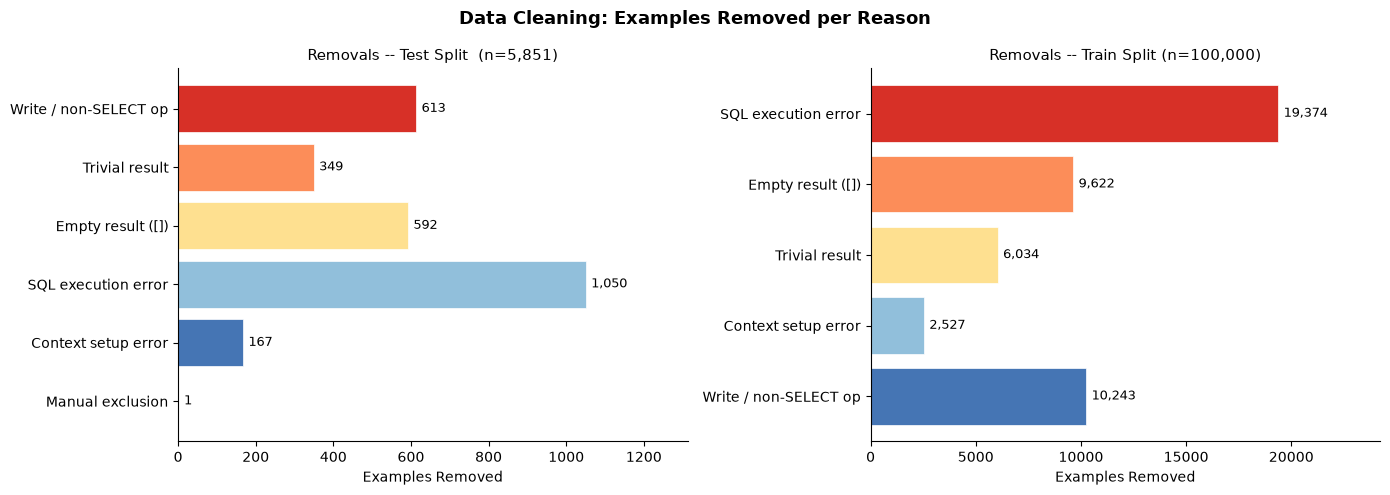

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#4575b4", "#74add1", "#313695"]

for ax, (counts, split_name) in zip(axes, [
    (test_reason_counts,  f"Test Split  (n={len(raw_test):,})"),
    (train_reason_counts, f"Train Split (n={len(raw_train):,})"),
]):
    labels, values = list(counts.keys()), list(counts.values())
    bars = ax.barh(labels, values, color=palette[:len(labels)], edgecolor="white", linewidth=0.5)
    ax.set_xlabel("Examples Removed")
    ax.set_title(f"Removals -- {split_name}", fontsize=11)
    ax.bar_label(bars, labels=[f"{v:,}" for v in values], padding=4, fontsize=9)
    ax.set_xlim(0, max(values) * 1.25 if values else 1)
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Data Cleaning: Examples Removed per Reason", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.6 Generate the splits
1. 200 clean test examples from `clean_test`, stratified by `sql_complexity` (first 20 = QUICK_RUN subset).
2. 200 clean validation examples from the *remaining* clean test pool (disjoint from test).
3. Train = every clean train example (the RAG index and any fine-tuning use this only).

In [60]:
rng = random.Random(SEED)
test_rows, remainder = data.stratified_sample(clean_test, TEST_SIZE, rng)
val_rows, _ = data.stratified_sample(remainder, VAL_SIZE, rng)

test_ids = [r["id"] for r in test_rows]
val_ids = [r["id"] for r in val_rows]
train_ids = [r["id"] for r in clean_train]

data.save_json_list(test_ids_path, test_ids)
data.save_json_list(val_ids_path, val_ids)
data.save_json_list(train_ids_path, train_ids)

test_set, val_set = set(test_ids), set(val_ids)
assert not (test_set & val_set), "ERROR: test and val share IDs!"
print("Disjointness checks:")
print(f"  test & val ID overlap: {len(test_set & val_set)} [OK]")

print("\nFinal split sizes:")
print(f"  {test_ids_path.name:<15}: {len(test_ids):,} examples  (first {QUICK_TEST} = QUICK_RUN)")
print(f"  {val_ids_path.name:<15}: {len(val_ids):,} examples")
print(f"  {train_ids_path.name:<15}: {len(train_ids):,} examples")
print(f"\nQUICK_RUN subset (first {QUICK_TEST} test IDs):\n  {test_ids[:QUICK_TEST]}")

Disjointness checks:
  test & val ID overlap: 0 [OK]

Final split sizes:
  test_ids.json  : 200 examples  (first 20 = QUICK_RUN)
  val_ids.json   : 200 examples
  train_ids.json : 52,200 examples

QUICK_RUN subset (first 20 test IDs):
  [5610, 1460, 1928, 4929, 4484, 4644, 3510, 2691, 773, 620, 4542, 2914, 2740, 4669, 5278, 4778, 18, 1175, 1301, 5194]


In [61]:
test_comp = Counter(r["sql_complexity"] for r in test_rows)
val_comp = Counter(r["sql_complexity"] for r in val_rows)
train_comp = Counter(r["sql_complexity"] for r in clean_train)
all_comps = sorted(set(test_comp) | set(val_comp) | set(train_comp))

print("SQL Complexity Distribution:")
print(f"  {'Complexity':<25} {'Train':>9} {'Val':>6} {'Test':>6}")
print("  " + "-" * 52)
for comp in all_comps:
    print(f"  {comp:<25} {train_comp.get(comp, 0):>9,d} {val_comp.get(comp, 0):>6,d} {test_comp.get(comp, 0):>6,d}")

SQL Complexity Distribution:
  Complexity                    Train    Val   Test
  ----------------------------------------------------
  aggregation                  12,742     49     49
  basic SQL                    26,574    104    102
  multiple_joins                  903      3      4
  set operations                  537      2      2
  single join                   6,878     26     27
  subqueries                    2,610      8      9
  window functions              1,956      8      7


### 1.7 EDA: SQL complexity distribution

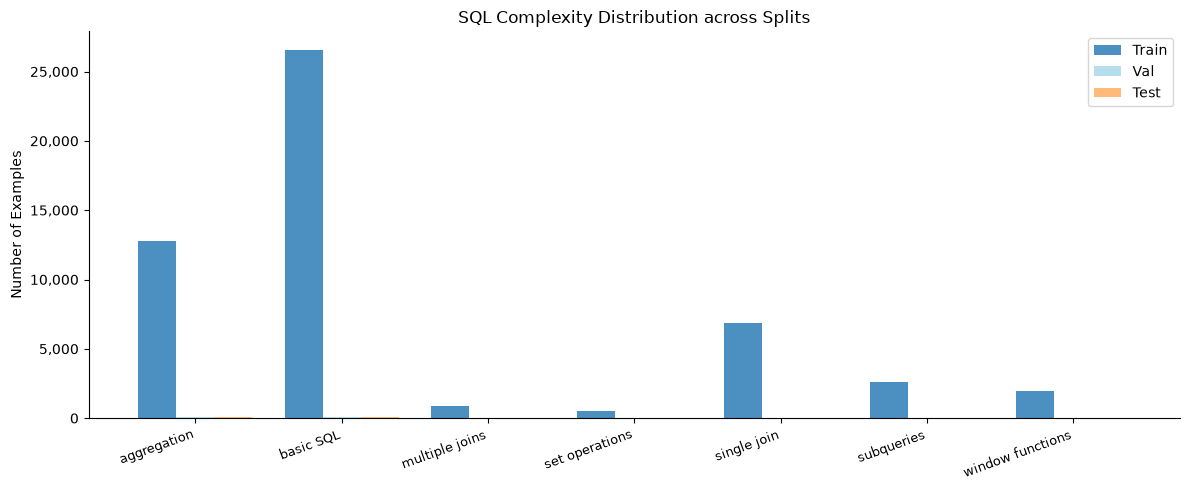

In [62]:
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(all_comps)); width = 0.26
colors = ["#2c7bb6", "#abd9e9", "#fdae61"]
ax.bar([i - width for i in x], [train_comp.get(c, 0) for c in all_comps], width, label="Train", color=colors[0], alpha=0.85)
ax.bar([i for i in x],         [val_comp.get(c, 0) for c in all_comps],   width, label="Val",   color=colors[1], alpha=0.85)
ax.bar([i + width for i in x], [test_comp.get(c, 0) for c in all_comps],  width, label="Test",  color=colors[2], alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels([c.replace("_", " ") for c in all_comps], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Number of Examples")
ax.set_title("SQL Complexity Distribution across Splits", fontsize=12)
ax.legend()
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 1.8 EDA: top 20 domains (clean train)

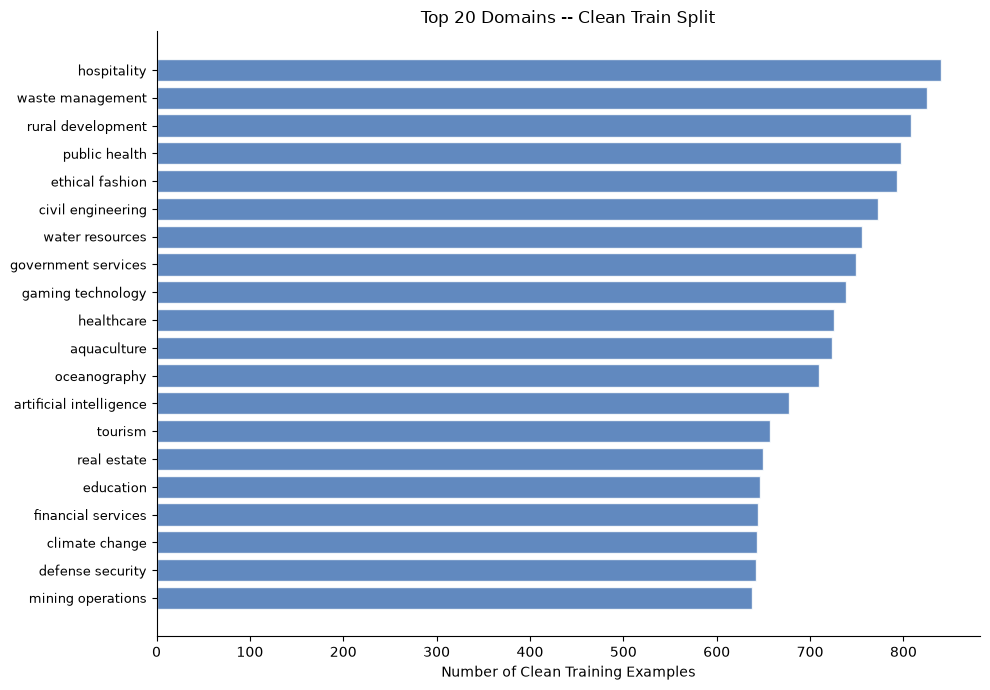

Total unique domains in clean train: 100


In [63]:
domain_counts = Counter(r["domain"] for r in clean_train)
labels, values = zip(*domain_counts.most_common(20))

fig, ax = plt.subplots(figsize=(10, 7))
y = range(len(labels))
ax.barh(list(y), list(values), color="#4575b4", alpha=0.85, edgecolor="white")
ax.set_yticks(list(y)); ax.set_yticklabels(list(labels), fontsize=9)
ax.set_xlabel("Number of Clean Training Examples")
ax.set_title("Top 20 Domains -- Clean Train Split", fontsize=12)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Total unique domains in clean train: {len(domain_counts)}")

### 1.9 EDA: prompt and SQL length distributions

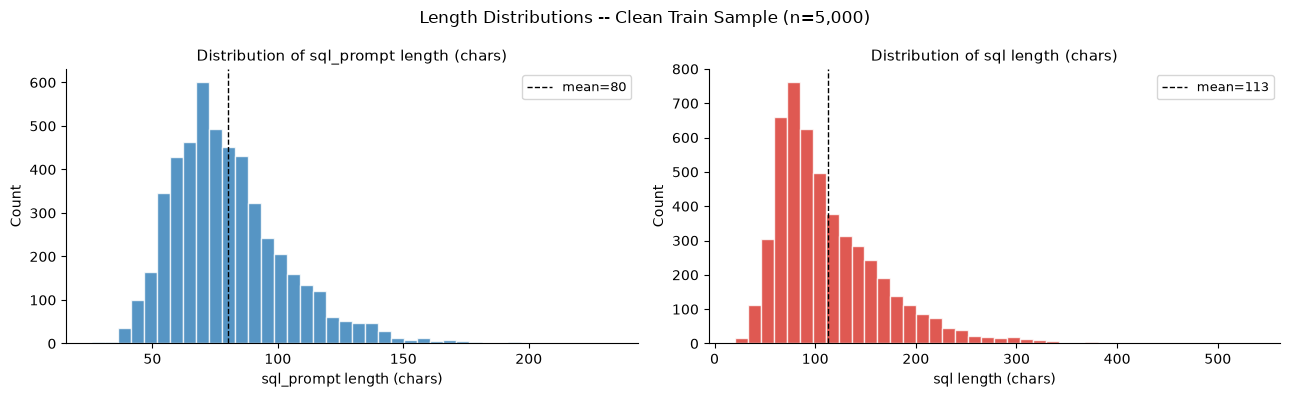

In [64]:
sample = random.Random(SEED).sample(clean_train, min(5000, len(clean_train)))
prompt_lens = [len(r["sql_prompt"]) for r in sample]
sql_lens = [len(r["sql"]) for r in sample]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, vals, label, color in zip(axes, [prompt_lens, sql_lens],
                                  ["sql_prompt length (chars)", "sql length (chars)"], ["#2c7bb6", "#d73027"]):
    mean = sum(vals) / len(vals)
    ax.hist(vals, bins=40, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(mean, color="black", linestyle="--", linewidth=1, label=f"mean={mean:.0f}")
    ax.set_xlabel(label); ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label}", fontsize=11)
    ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Length Distributions -- Clean Train Sample (n=5,000)", fontsize=12)
plt.tight_layout()
plt.show()

### 1.10 Overlap and leakage report

In [65]:
test_prompts = {r["sql_prompt"] for r in test_rows}
val_prompts = {r["sql_prompt"] for r in val_rows}
train_prompts = {r["sql_prompt"] for r in clean_train}

print("Prompt overlap (must be 0):")
print(f"  test  & train prompt overlap: {len(test_prompts & train_prompts):,}")
print(f"  val   & train prompt overlap: {len(val_prompts & train_prompts):,}")
print(f"  test  & val   prompt overlap: {len(test_prompts & val_prompts):,}")
assert not (test_prompts & train_prompts), "ERROR: test/train prompt leakage"
assert not (val_prompts & train_prompts), "ERROR: val/train prompt leakage"
assert not (test_prompts & val_prompts), "ERROR: test/val prompt overlap"

# Full official train/test pools can reuse numeric IDs; prompts are the leakage key.
test_contexts = {r["sql_context"] for r in test_rows}
val_contexts = {r["sql_context"] for r in val_rows}
train_contexts = {r["sql_context"] for r in clean_train}
print("\nsql_context (table schema) overlap:")
print(f"  test  & train context overlap: {len(test_contexts & train_contexts):,}  (shared table schemas)")
print(f"  val   & train context overlap: {len(val_contexts & train_contexts):,}  (shared table schemas)")
print("  Note: shared schemas are expected in a synthetic dataset;")
print("  what matters is that prompts and IDs do not overlap (all 0 above).")

print("\nLeakage safeguard:")
print("  * selected prompts are disjoint across train, val, and test")
print("  * The RAG index (Part 2) is built from train prompts only")
print("  * Do not index or train on any validation or test prompt")

Prompt overlap (must be 0):
  test  & train prompt overlap: 0
  val   & train prompt overlap: 0
  test  & val   prompt overlap: 0

sql_context (table schema) overlap:
  test  & train context overlap: 18  (shared table schemas)
  val   & train context overlap: 20  (shared table schemas)
  Note: shared schemas are expected in a synthetic dataset;
  what matters is that prompts and IDs do not overlap (all 0 above).

Leakage safeguard:
  * selected prompts are disjoint across train, val, and test
  * The RAG index (Part 2) is built from train prompts only
  * Do not index or train on any validation or test prompt


### 1.11 SQL harness self-tests

In [66]:
data.self_test_harness()
print("\nHarness self-tests complete.")

All 4 self-tests passed [OK]

Harness self-tests complete.


### 1.12 Filter report
`MANUAL_AUDIT` holds the summary of the manual review that is written to `filter_report.json`. When it is `None`, the default entry defined in `data.py` is used.

In [67]:
MANUAL_AUDIT = None

report = data.generate_filter_report(
    test_log=test_log, train_log=train_log,
    test_ids=test_ids, val_ids=val_ids, train_ids=train_ids,
    test_raw=len(raw_test), train_raw=len(raw_train),
    manual_audit=MANUAL_AUDIT,
)

print("\n=== Filter Report Summary ===")
print(f"\nTest split ({report['test_split']['raw_total']:,} raw):")
for reason, count in report["test_split"]["removed_by_reason"].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean pool                  : {report['test_split']['clean_pool_size']:,}")

print(f"\nTrain split ({report['train_split']['raw_total']:,} raw):")
for reason, count in report["train_split"]["removed_by_reason"].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean total                 : {report['train_split']['clean_total']:,}")

print("\nFinal splits:")
for k, v in report["final_splits"].items():
    print(f"  {k:<25}: {v:,}")
print(f"\nManual audit status: {report['manual_audit']['status']}")

Filter report saved -> filter_report.json

=== Filter Report Summary ===

Test split (5,851 raw):
  write_or_non_select         : 613
  trivial_result              : 349
  empty_result                : 592
  sql_execution_error         : 1,050
  context_setup_error         : 167
  manual_exclusion            : 1
  Clean pool                  : 3,079

Train split (100,000 raw):
  sql_execution_error         : 19,374
  empty_result                : 9,622
  trivial_result              : 6,034
  context_setup_error         : 2,527
  write_or_non_select         : 10,243
  Clean total                 : 52,200

Final splits:
  test                     : 200
  val                      : 200
  train_clean_total        : 52,200
  quick_run_subset         : 20

Manual audit status: pending manual review (1 example pre-flagged as reference)


### 1.13 Consistency check against the reference figures

In [68]:
REFERENCE = {"clean test pool": (len(clean_test), 3078), "clean train": (len(clean_train), 52181),
             "test": (len(test_ids), 200), "val": (len(val_ids), 200)}
for name, (got, ref) in REFERENCE.items():
    print(f"  {name:<16}: {got:>7,d}  (reference: {ref:,})  {'[OK]' if got == ref else '[differs]'}")
print("\nDifferences arise only when additional manual exclusions are recorded in excluded_ids.json.")

  clean test pool :   3,079  (reference: 3,078)  [differs]
  clean train     :  52,200  (reference: 52,181)  [differs]
  test            :     200  (reference: 200)  [OK]
  val             :     200  (reference: 200)  [OK]

Differences arise only when additional manual exclusions are recorded in excluded_ids.json.


### 1.14 Manual audit
Examples that pass every filter can still be unsuitable: the gold SQL may not answer the question, the question may be ambiguous, or the result may be trivial. `AUDIT_N` test examples are displayed in blocks of ten (`AUDIT_START` = 0, 10, 20, ...). Examples judged unsuitable are added to `test_exclusions` in `excluded_ids.json`, after which Part 1 is re-run.

In [69]:
AUDIT_N, AUDIT_START = 60, 0
test_idx = {i: k for k, i in enumerate(raw_test["id"])}

def show_audit(split, index, ids, start=0, n=10):
    for i in ids[start:start + n]:
        ex = split[index[i]]
        rows, err = run_sql(ex["sql_context"], ex["sql"])
        print("=" * 70)
        print(f"id {i} | {ex['sql_complexity']} | {ex['domain']}")
        print("Q:     ", ex["sql_prompt"])
        print("SCHEMA:", ex["sql_context"][:350].replace("\n", " "))
        print("GOLD:  ", ex["sql"])
        print("RESULT:", (rows or [])[:5], f"({len(rows or [])} rows)")

show_audit(raw_test, test_idx, test_ids[:AUDIT_N], start=AUDIT_START, n=10)

id 5610 | basic SQL | space
Q:      Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites.
SCHEMA: CREATE TABLE gso_debris (id INT, name VARCHAR(50), type VARCHAR(50), orbit VARCHAR(50), mass FLOAT, source VARCHAR(50)); INSERT INTO gso_debris (id, name, type, orbit, mass, source) VALUES (1, 'Debris1', 'Panel', 'GSO', 50.3, 'Defunct Satellite'), (2, 'Debris2', 'Bolt', 'GSO', 0.05, 'Rocket Body'), (3, 'Debris3', 'Rod', 'GSO', 2.8, 'Defunct Satelli
GOLD:   SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite';
RESULT: [(53.099999999999994,)] (1 rows)
id 1460 | aggregation | humanitarian aid
Q:      Which region has the highest average shelter capacity?
SCHEMA: CREATE TABLE region (region_id INT, name VARCHAR(255)); INSERT INTO region (region_id, name) VALUES (1, 'west_africa'), (2, 'east_asia'), (3, 'south_america'); CREATE TABLE shelter (shelter_id INT, name VARCHAR(255), region_id INT, capacity INT); I

### 1.15 Runtime summary

In [70]:
elapsed = time.time() - _notebook_start
print(f"Part 1 completed in {elapsed:.1f} seconds ({elapsed / 60:.1f} minutes)")
print("Files saved:")
for fname in [test_ids_path.name, val_ids_path.name, train_ids_path.name, excluded_path.name, Path(CONFIG.get("filter_report_path", "filter_report.json")).name,
              "cleaning_removal_reasons.png", "eda_complexity_distribution.png",
              "eda_domain_distribution.png", "eda_length_distributions.png"]:
    p = Path(fname)
    print(f"  {fname:<40} {f'{p.stat().st_size:,} bytes' if p.exists() else 'NOT FOUND'}")

Part 1 completed in 10.5 seconds (0.2 minutes)
Files saved:
  test_ids.json                            1,560 bytes
  val_ids.json                             1,566 bytes
  train_ids.json                           463,988 bytes
  excluded_ids.json                        297 bytes
  filter_report.json                       1,128 bytes
  cleaning_removal_reasons.png             NOT FOUND
  eda_complexity_distribution.png          NOT FOUND
  eda_domain_distribution.png              NOT FOUND
  eda_length_distributions.png             NOT FOUND


# Part 2: Retrieval-augmented generation

Few-shot examples are retrieved from the clean training split and inserted into the prompt of a SQLite text-to-SQL model. Generated queries are executed against the example's database and counted as correct when the result matches the gold query's result (execution accuracy).

**Design decisions**
- *Splits.* The validation set (`val_ids.json`) and the test set (`test_ids.json`) are drawn from the official test split in proportion to SQL complexity, so both measure the same distribution. The retrieval index is built from `train_ids.json` only, after removing any question that also occurs in validation or test.
- *Model selection.* All retrieval settings and the prompt style are selected on the validation set. The test set is evaluated once.
- *Prompt styles.* Two prompt styles are compared on validation. **original**: example schemas are shown as `CREATE TABLE` statements, the target schema in full, and `SELECT *` is forbidden. **strict**: example schemas are shown in full, examples are numbered, and the model is instructed to use only the tables and columns of the final schema.

### 2.1 Settings

In [71]:
K_GRID = [3, 5]               # number of retrieved examples to compare
RUN_SKELETON = True           # skeleton retrieval is slower (needs a zero-shot draft); set False to skip
BATCH_SIZE = 4
PROMPT_STYLE = "auto"         # "original" | "strict" | "auto" (selected on validation in 2.7)
INDEX_N = None                # optional cap on the index size

QUICK_VAL = 40
print(f"Quick Run: {QUICK_RUN} | INDEX_N: {INDEX_N} | K_GRID: {K_GRID} | skeleton: {RUN_SKELETON}")

Quick Run: False | INDEX_N: None | K_GRID: [3, 5] | skeleton: True


### 2.2 Splits from the saved ID files
Validation and test examples come from the official test split and training examples from the official train split. Part 2 uses the ID files written in Part 1; no further splitting takes place.

In [72]:
def pick(split, ids):
    idx = {i: k for k, i in enumerate(split["id"])}
    return split.select([idx[i] for i in ids if i in idx])

train_all = pick(raw_train, train_ids)
val_ds = pick(raw_test, val_ids)
test_ds = pick(raw_test, test_ids)
print("train:", len(train_all), "| val:", len(val_ds), "| test:", len(test_ds))

val_eval = val_ds.select(range(min(QUICK_VAL, len(val_ds)))) if QUICK_RUN else val_ds
test_eval = test_ds.select(range(min(QUICK_TEST, len(test_ds)))) if QUICK_RUN else test_ds

train: 52200 | val: 200 | test: 200


### 2.3 Schema helpers and question masking
Masking replaces table names, column names, quoted values and numbers in the question with placeholders, so retrieval matches the *shape* of the question rather than its topic words.

In [73]:
SCHEMA_MODE = "full"          # "full" = whole sql_context, "create" = CREATE statements only

def schema_text(ctx, mode=None):
    mode = mode or SCHEMA_MODE
    if mode == "create":
        stmts = re.findall(r"CREATE\s+TABLE[^;]*;", ctx, flags=re.I | re.S)
        return "\n".join(stmts) if stmts else ctx
    return ctx

def schema_names(ctx):
    """Table and column names from the CREATE TABLE statements."""
    tables, cols = set(), set()
    pat = r"CREATE\s+TABLE\s+(?:IF NOT EXISTS\s+)?[`\"\[]?(\w+)[`\"\]]?\s*\((.*?)\)\s*;"
    for m in re.finditer(pat, ctx, flags=re.I | re.S):
        tables.add(m.group(1))
        depth, cur, parts = 0, "", []
        for ch in m.group(2):
            if ch == "(":
                depth += 1
            if ch == ")":
                depth -= 1
            if ch == "," and depth == 0:
                parts.append(cur); cur = ""
            else:
                cur += ch
        parts.append(cur)
        for p in parts:
            tok = p.strip().split()
            if tok and tok[0].upper() not in ("PRIMARY", "FOREIGN", "UNIQUE", "CONSTRAINT", "CHECK"):
                cols.add(tok[0].strip('`"[]'))
    return tables, cols

def mask_question(q, ctx):
    tables, cols = schema_names(ctx)
    out = q
    names = [(n, "<T>") for n in sorted(tables, key=len, reverse=True)] + \
            [(n, "<C>") for n in sorted(cols, key=len, reverse=True)]
    for name, tag in names:
        for v in sorted({name, name.replace("_", " ")}, key=len, reverse=True):
            out = re.sub(rf"\b{re.escape(v)}s?\b", tag, out, flags=re.I)
    out = re.sub(r"'[^']*'|\"[^\"]*\"", "<V>", out)
    out = re.sub(r"\b\d[\d,\.]*\b", "<N>", out)
    return out

for ex in test_ds.select(range(3)):
    print(ex["sql_prompt"], "\n  ->", mask_question(ex["sql_prompt"], ex["sql_context"]))

Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites. 
  -> Find the total <C> of all space debris in Geostationary <C> (GSO) that originate from defunct satellites.
Which region has the highest average shelter capacity? 
  -> Which <T> has the highest average <T> <C>?
Who were the top 3 volunteer programs by total hours in 2023? 
  -> Who were the top <N> volunteer programs by total hours in <N>?


### 2.4 Build the indexes (from the clean train split only)
The retrieval pool is `train_ids.json` minus (a) any question that also appears in validation or test, and (b) repeated questions. The shared ID files are not touched.

In [74]:
# Safe defaults if previous settings cells were skipped
from pathlib import Path

INDEX_N = globals().get("INDEX_N", None)
SEED = globals().get("SEED", 42)
CACHE = globals().get("CACHE", Path("clean_data"))
if "CONFIG" not in globals():
    from config import CONFIG

import torch, faiss, hashlib
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi

norm = lambda s: re.sub(r"\s+", " ", s.lower().strip())
blocked = {norm(q) for q in val_ds["sql_prompt"]} | {norm(q) for q in test_ds["sql_prompt"]}

seen, keep, n_leak, n_dup = set(), [], 0, 0
for k, q in enumerate(train_all["sql_prompt"]):
    nq = norm(q)
    if nq in blocked: n_leak += 1; continue
    if nq in seen: n_dup += 1; continue
    seen.add(nq); keep.append(k)

pool = train_all.select(keep)
if INDEX_N is not None:
    pool = pool.shuffle(seed=SEED).select(range(min(INDEX_N, len(pool))))
pool_q, pool_ctx, pool_sql = pool["sql_prompt"], pool["sql_context"], pool["sql"]
print(f"train {len(train_all):,} -> index {len(pool_q):,} (dropped {n_leak} val/test questions, {n_dup} repeated questions)")

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(CONFIG["embedder"], device=device)

def embed(texts, bar=False):
    return embedder.encode(texts, batch_size=128, normalize_embeddings=True, show_progress_bar=bar).astype("float32")

def cached_embed(tag, texts):
    """Embeddings are cached on disk, keyed by model name and text, so re-runs are instant."""
    key = hashlib.md5((CONFIG["embedder"] + "\n".join(texts)).encode()).hexdigest()[:10]
    f = CACHE / f"emb_{tag}_{key}.npy"
    if f.exists():
        return np.load(f)
    v = embed(texts, bar=True); np.save(f, v)
    return v

def build_faiss(vecs):
    index = faiss.IndexFlatIP(vecs.shape[1]); index.add(vecs)
    return index

pool_masked = [mask_question(q, c) for q, c in zip(pool_q, pool_ctx)]
index_dense = build_faiss(cached_embed("dense", pool_q))
index_masked = build_faiss(cached_embed("masked", pool_masked))
tokenize = lambda s: re.findall(r"\w+", s.lower())
bm25 = BM25Okapi([tokenize(q) for q in pool_q])

# leakage check: no validation or test question may be inside the index
leak = {norm(q) for q in pool_q} & blocked
print("val/test questions found in the index:", len(leak))
assert not leak

train 52,200 -> index 52,179 (dropped 0 val/test questions, 21 repeated questions)


Batches: 100%|██████████| 408/408 [00:05<00:00, 71.06it/s]


val/test questions found in the index: 0


### 2.5 `retrieve` (dense, bm25, hybrid RRF, masked) and skeleton retrieval

In [75]:
# Safe defaults
K_GRID = globals().get("K_GRID", [3, 5])

def _dense(index, text, n):
    _, I = index.search(embed([text]), n)
    return [int(i) for i in I[0] if i >= 0]

def _bm25(text, n):
    return [int(i) for i in np.argsort(-bm25.get_scores(tokenize(text)))[:n]]

def _rrf(*rankings):
    score = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking):
            score[i] = score.get(i, 0) + 1 / (60 + rank + 1)
    return sorted(score, key=score.get, reverse=True)

def _as_examples(ids):
    return [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in ids]

def retrieve(question, k=3, mode="dense", schema=None):
    """Return k similar solved examples. mode: dense | bm25 | hybrid (RRF) | masked."""
    if k == 0:
        return []
    if mode == "dense":
        ids = _dense(index_dense, question, k)
    elif mode == "bm25":
        ids = _bm25(question, k)
    elif mode == "hybrid":
        ids = _rrf(_dense(index_dense, question, 50), _bm25(question, 50))[:k]
    elif mode == "masked":
        ids = _dense(index_masked, mask_question(question, schema or ""), k)
    else:
        raise ValueError(mode)
    return _as_examples(ids)

def random_examples(q, k=3):
    return _as_examples(random.Random(f"{SEED}-{q}").sample(range(len(pool_q)), k))

# ---- skeleton retrieval: match the *SQL shape* of a zero-shot draft ----
KW = set("""SELECT FROM WHERE GROUP BY ORDER HAVING JOIN INNER LEFT RIGHT OUTER FULL CROSS ON AS AND OR NOT IN EXISTS UNION ALL INTERSECT EXCEPT LIMIT OFFSET DISTINCT COUNT SUM AVG MIN MAX OVER PARTITION CASE WHEN THEN ELSE END LIKE BETWEEN IS NULL DESC ASC WITH ROW_NUMBER RANK DENSE_RANK LAG LEAD""".split())

def skeleton(sql):
    s = re.sub(r"'[^']*'", " <V> ", sql)
    s = re.sub(r"\b\d+(?:\.\d+)?\b", " <N> ", s)
    out = []
    for t in re.findall(r"<V>|<N>|\w+|[^\s\w]", s):
        if t in ("<V>", "<N>") or not re.match(r"\w", t): out.append(t)
        elif t.upper() in KW: out.append(t.upper())
        else: out.append("<I>")
    return " ".join(out)

if RUN_SKELETON:
    bm25_skel = BM25Okapi([skeleton(s).split() for s in pool_sql])

def retrieve_skeleton(question, ctx, k, draft):
    r1 = _dense(index_masked, mask_question(question, ctx), 50)
    r2 = [int(i) for i in np.argsort(-bm25_skel.get_scores(skeleton(draft).split()))[:50]]
    return _as_examples(_rrf(r1, r2)[:k])

ex = val_ds[0]
for r in retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"]):
    print(r["sql_prompt"], "->", r["sql"])

What is the average account balance for clients in Oceania in Q2 2022? -> SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('Australia', 'New Zealand', 'Papua New Guinea') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';
What is the average account balance for clients in the Southeast region? -> SELECT AVG(balance) FROM accounts WHERE region = 'Southeast';
What is the average financial wellbeing score for customers in Asia in 2021? -> SELECT AVG(score) FROM financial_wellbeing WHERE region = 'Asia' AND year = 2021;


### 2.6 `generate` (zero-shot, few-shot, batched) and `evaluate`
Two prompt styles are compared in 2.7:
- **original**: example schemas are shown as `CREATE TABLE` statements only, the target schema in full, and `SELECT *` is forbidden.
- **strict**: the later prompt. Examples show the full schema (with `INSERT` rows), numbered headers, and an instruction to use only the last schema.

In [76]:
# Safe defaults
BATCH_SIZE = globals().get("BATCH_SIZE", 4)
PROMPT_STYLE = globals().get("PROMPT_STYLE", "strict")
if "device" not in globals():
    import torch
    device = "cuda" if torch.cuda.is_available() else "cpu"

from transformers import AutoTokenizer, AutoModelForCausalLM

llm_tok = AutoTokenizer.from_pretrained(CONFIG["llm"])
if llm_tok.pad_token is None:
    llm_tok.pad_token = llm_tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["llm"], dtype=torch.float16 if device == "cuda" else torch.float32
).to(device).eval()

SYSTEM_ORIGINAL = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. Return only the SQL. "
    "Use ONLY SQLite-compatible syntax - do NOT use YEAR(), MONTH(), DATE_FORMAT(), or any MySQL function. "
    "For dates use strftime() or string comparison. "
    "Never use SELECT * - always select only the columns the question asks for. "
    "Return only the SQL query, do not include any explanation or additional text, no markdown."
)
SYSTEM_STRICT = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. "
    "Use ONLY SQLite-compatible syntax: no YEAR(), MONTH(), DATE_FORMAT() or other MySQL functions. "
    "For dates use strftime() or string comparison. "
    "Use ONLY the table and column names from the LAST schema given. "
    "Return only the SQL, with no explanation and no markdown."
)
PROMPTS = {"original": dict(system=SYSTEM_ORIGINAL, ex_schema="create", numbered=False),
           "strict":   dict(system=SYSTEM_STRICT,   ex_schema="full",   numbered=True)}

def build_messages(question, schema, examples=None, style="original"):
    p = PROMPTS[style]
    parts = []
    for n, e in enumerate(examples or [], 1):
        head = f"### Example {n}\n" if p["numbered"] else ""
        parts.append(f"{head}Schema:\n{schema_text(e['sql_context'], mode=p['ex_schema'])}\n"
                     f"Question: {e['sql_prompt']}\nSQL: {e['sql']}")
    head = "### Now solve this one. Use ONLY the tables and columns in this schema.\n" if p["numbered"] else ""
    parts.append(f"{head}Schema:\n{schema_text(schema, mode='full')}\nQuestion: {question}\nSQL:")
    return [{"role": "system", "content": p["system"]}, {"role": "user", "content": "\n\n".join(parts)}]

def clean_sql(text):
    text = re.sub(r"```(?:sql)?", "", text, flags=re.I).strip()
    text = re.sub(r"^\s*SQL:\s*", "", text, flags=re.I)
    stmt = text.split(";")[0].strip()
    return stmt + ";" if stmt else ""

def generate_batch(items, style="original", batch_size=BATCH_SIZE):
    """items: list of (question, schema, examples or None). Returns SQL strings in the same order."""
    texts = [llm_tok.apply_chat_template(build_messages(q, s, e, style), tokenize=False, add_generation_prompt=True)
             for q, s, e in items]
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))    # similar lengths together = less padding
    outs = [None] * len(texts)
    llm_tok.padding_side = "left"
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        inputs = llm_tok([texts[i] for i in idx], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=256, do_sample=False,
                               pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id)
        for j, i in enumerate(idx):
            outs[i] = clean_sql(llm_tok.decode(out[j][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
    return outs

def generate(question, schema, examples=None, style="original"):
    """examples=None -> zero-shot, otherwise few-shot. Returns one SQL string."""
    return generate_batch([(question, schema, examples)], style, 1)[0]

ex = val_ds[0]
print("gold:", ex["sql"])
print("zero:", generate(ex["sql_prompt"], ex["sql_context"]))
print("few: ", generate(ex["sql_prompt"], ex["sql_context"], retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"])))

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 2637.83it/s]


gold: SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('India', 'China', 'Japan') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';
zero: SELECT AVG(balance) FROM accounts WHERE strftime('%Y-%m', account_date) BETWEEN '2022-04' AND '2022-06' AND country IN ('India', 'China');
few:  SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('China', 'Japan') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';


In [77]:
# Safe defaults
RUN_SKELETON = globals().get("RUN_SKELETON", True)
K_GRID = globals().get("K_GRID", [3, 5])

def evaluate_batched(name, subset, examples_list, style, t0=None):
    """Runs generation for every example, executes pred and gold, saves per-example results to results/<name>.json."""
    t0 = t0 or time.time()
    subset = list(subset)
    preds = generate_batch([(e["sql_prompt"], e["sql_context"], x) for e, x in zip(subset, examples_list)], style)
    per_ex = round((time.time() - t0) / max(len(subset), 1), 3)
    rows = []
    for e, pred in zip(subset, preds):
        p_rows, err = run_sql(e["sql_context"], pred)
        g_rows, _ = run_sql(e["sql_context"], e["sql"])
        rows.append({"id": e["id"], "complexity": e["sql_complexity"], "question": e["sql_prompt"],
                     "pred": pred, "gold": e["sql"], "error": err,
                     "correct": bool(err is None and same_result(p_rows, g_rows)), "sec": per_ex})
    df = pd.DataFrame(rows)
    Path("results").mkdir(exist_ok=True)
    df.to_json(f"results/{name}.json", orient="records", indent=1)
    return df

def run_system(name, mode, k, subset, style, tag=None):
    """mode: zero | random | dense | bm25 | hybrid | masked | skeleton. Includes retrieval time in `sec`."""
    t0 = time.time()
    subset = list(subset)
    if mode == "zero":
        exs = [None] * len(subset)
    elif mode == "random":
        exs = [random_examples(e["sql_prompt"], k) for e in subset]
    elif mode == "skeleton":
        drafts = generate_batch([(e["sql_prompt"], e["sql_context"], None) for e in subset], style)
        exs = [retrieve_skeleton(e["sql_prompt"], e["sql_context"], k, d) for e, d in zip(subset, drafts)]
    else:
        exs = [retrieve(e["sql_prompt"], k, mode, schema=e["sql_context"]) for e in subset]
    return evaluate_batched(tag or name, subset, exs, style, t0)

def paired_gain(name, base="zero_shot", n=2000, seed=0):
    """Mean accuracy gain over `base` on the same questions, with a paired-bootstrap 95% CI."""
    a = pd.read_json(f"results/{base}.json").set_index("id").correct.astype(float)
    b = pd.read_json(f"results/{name}.json").set_index("id").correct.astype(float)
    d = (b - a.loc[b.index]).values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d)).mean() for _ in range(n)]
    return round(d.mean(), 3), tuple(np.percentile(m, [2.5, 97.5]).round(3))

SYSTEMS = {"zero_shot": ("zero", 0), "random_k3": ("random", 3)}
for mode in ["dense", "bm25", "hybrid", "masked"]:
    for k in K_GRID:
        SYSTEMS[f"{mode}_k{k}"] = (mode, k)
if RUN_SKELETON:
    SYSTEMS["skeleton_k3"] = ("skeleton", 3)
print(list(SYSTEMS))

['zero_shot', 'random_k3', 'dense_k3', 'dense_k5', 'bm25_k3', 'bm25_k5', 'hybrid_k3', 'hybrid_k5', 'masked_k3', 'masked_k5', 'skeleton_k3']


### 2.7 Compare settings on the validation set
All settings are selected on the validation set; the test set is not used for tuning.

**Step 1: prompt ablation.** Three representative systems are evaluated under both prompt styles. The style with the higher mean validation accuracy is used in all subsequent runs, unless `PROMPT_STYLE` is set explicitly.

In [78]:
from pathlib import Path
import shutil

# If validation results already exist from Part 2, reuse them; set RECOMPUTE = True to rerun
RECOMPUTE = False
val_table_path = Path("results/val_table.csv")

if not val_table_path.exists() or RECOMPUTE:
    shutil.rmtree("results", ignore_errors=True)
    ABLATE = ["zero_shot", "bm25_k3", "masked_k3"]
    abl = []
    for style in PROMPTS:
        for name in ABLATE:
            mode, k = SYSTEMS[name]
            d = run_system(name, mode, k, val_eval, style, tag=f"abl_{style}_{name}")
            abl.append({"style": style, "system": name, "exec_acc": round(d.correct.mean(), 3)})
    abl = pd.DataFrame(abl).pivot(index="style", columns="system", values="exec_acc")[ABLATE]
    abl["mean"] = abl.mean(axis=1).round(3)
    display(abl)
    if PROMPT_STYLE == "auto":
        PROMPT_STYLE = abl["mean"].idxmax()
else:
    print("Found pre-computed validation results in results/ -- skipping re-generation.")
    if PROMPT_STYLE == "auto":
        PROMPT_STYLE = "strict"

print("Prompt style used from here on:", PROMPT_STYLE)


Found pre-computed validation results in results/ -- skipping re-generation.
Prompt style used from here on: strict


**Step 2: retrieval settings.** Zero-shot, random examples, dense, BM25, hybrid, masked and skeleton retrieval, with k in `K_GRID`.

In [79]:
table = []
for name, (mode, k) in SYSTEMS.items():
    df = run_system(name, mode, k, val_eval, PROMPT_STYLE)
    row = {"system": name, "exec_acc": round(df.correct.mean(), 3), "avg_sec": round(df.sec.mean(), 2)}
    if name != "zero_shot":
        g, ci = paired_gain(name)
        row["gain_vs_zero"], row["95% CI"] = g, ci
    table.append(row)
val_table = pd.DataFrame(table)
display(val_table)
val_table.to_csv("results/val_table.csv", index=False)

accs = {n: pd.read_json(f"results/{n}.json").groupby("complexity").correct.mean().round(2) for n in SYSTEMS}
print("\nAccuracy by SQL complexity (validation):")
display(pd.DataFrame(accs))

,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.570,0.19,NaN,NaN
1,random_k3,0.585,0.23,0.015,"(-0.03, 0.065)"
2,dense_k3,0.645,0.25,0.075,"(0.015, 0.135)"
3,dense_k5,0.665,0.29,0.095,"(0.035, 0.16)"
4,bm25_k3,0.695,0.33,0.125,"(0.055, 0.195)"
5,bm25_k5,0.670,0.36,0.100,"(0.03, 0.17)"
6,hybrid_k3,0.655,0.34,0.085,"(0.02, 0.15)"
7,hybrid_k5,0.675,0.36,0.105,"(0.045, 0.17)"
8,masked_k3,0.665,0.25,0.095,"(0.04, 0.155)"
9,masked_k5,0.665,0.29,0.095,"(0.035, 0.155)"



Accuracy by SQL complexity (validation):


,zero_shot,random_k3,dense_k3,dense_k5,bm25_k3,bm25_k5,hybrid_k3,hybrid_k5,masked_k3,masked_k5,skeleton_k3
complexity,,,,,,,,,,,
aggregation,0.39,0.41,0.65,0.61,0.71,0.71,0.63,0.67,0.63,0.61,0.61
basic SQL,0.74,0.76,0.81,0.80,0.79,0.79,0.79,0.80,0.79,0.77,0.79
multiple_joins,0.00,0.33,0.00,0.33,0.67,0.33,0.00,0.00,0.00,0.33,0.33
set operations,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
single join,0.46,0.46,0.38,0.50,0.54,0.42,0.50,0.54,0.58,0.54,0.54
subqueries,0.50,0.38,0.25,0.50,0.38,0.38,0.38,0.38,0.38,0.50,0.38
window functions,0.25,0.25,0.12,0.25,0.38,0.25,0.25,0.25,0.25,0.50,0.38


### 2.8 Error analysis: cases where retrieval hurt
Examples answered correctly in the zero-shot setting and incorrectly with the best retrieval setting. Typical causes are a misleading retrieved example and copied table or column names.

In [80]:
cands = val_table[~val_table.system.isin(["zero_shot", "random_k3"])].sort_values(["exec_acc", "avg_sec"], ascending=[False, True])
BEST = cands.iloc[0].system
print("Best retrieval setting on validation:", BEST, "| exec_acc:", cands.iloc[0].exec_acc)

a = pd.read_json("results/zero_shot.json")
b = pd.read_json(f"results/{BEST}.json")
m = a.merge(b, on="id", suffixes=("_zero", "_rag"))
hurt = m[m.correct_zero & ~m.correct_rag]
print(len(hurt), "examples where retrieval hurt\n")
for _, r in hurt.head(5).iterrows():
    print("ID:", r.id, "| Q:", r.question_zero, "\n gold:", r.gold_zero, "\n zero:", r.pred_zero,
          "\n rag: ", r.pred_rag, "\n err: ", r.error_rag, "\n")

Best retrieval setting on validation: bm25_k3 | exec_acc: 0.695
14 examples where retrieval hurt

ID: 4160 | Q: Find the ratio of community health workers to mental health professionals in each region. 
 gold: SELECT Region, AVG(CommunityHealthWorkerCount / MentalHealthProfessionalCount) AS Ratio FROM (SELECT Region, SUM(CASE WHEN WorkerType = 'MentalHealthProfessional' THEN Count ELSE 0 END) AS MentalHealthProfessionalCount, SUM(CASE WHEN WorkerType = 'CommunityHealthWorker' THEN Count ELSE 0 END) AS CommunityHealthWorkerCount FROM HealthWorkers GROUP BY Region) AS HealthWorkerCounts GROUP BY Region; 
 zero: SELECT Region, COUNT(CASE WHEN WorkerType = 'CommunityHealthWorker' THEN 1 END) / COUNT(*) AS CommunityHealthWorkerRatio FROM HealthWorkers GROUP BY Region; 
 rag:  SELECT Region, CAST(SUM(CASE WHEN WorkerType = 'CommunityHealthWorker' THEN Count ELSE 0 END) AS REAL) / SUM(Count) * 100 AS Ratio FROM HealthWorkers GROUP BY Region; 
 err:  nan 

ID: 287 | Q: What is the average ment

In [81]:
# Does retrieval make the model copy table/column names from the examples?
for n in ["zero_shot", "random_k3", "dense_k3", "bm25_k3", "masked_k3"] + (["skeleton_k3"] if RUN_SKELETON else []):
    e = pd.read_json(f"results/{n}.json").error.fillna("").str.lower()
    print(f"{n:<12} | no such table: {e.str.contains('no such table').mean():.3f}"
          f" | no such column: {e.str.contains('no such column').mean():.3f}"
          f" | any error: {(e != '').mean():.3f}")

zero_shot    | no such table: 0.025 | no such column: 0.040 | any error: 0.075
random_k3    | no such table: 0.000 | no such column: 0.030 | any error: 0.045
dense_k3     | no such table: 0.025 | no such column: 0.080 | any error: 0.125
bm25_k3      | no such table: 0.030 | no such column: 0.055 | any error: 0.090
masked_k3    | no such table: 0.010 | no such column: 0.050 | any error: 0.060
skeleton_k3  | no such table: 0.005 | no such column: 0.050 | any error: 0.060


### 2.9 Final test evaluation
Zero-shot generation, random examples and the best retrieval setting from the validation table are evaluated once on the test set.

In [82]:
RUN_TEST = True
mode_b, k_b = SYSTEMS[BEST]
FINAL = {"zero_shot": SYSTEMS["zero_shot"], "random_k3": SYSTEMS["random_k3"], BEST: (mode_b, k_b)}

test_file = Path(f"results/test_{BEST}.json")
if RUN_TEST:
    if not test_file.exists() or ('RECOMPUTE' in globals() and RECOMPUTE):
        rows = []
        for name, (mode, k) in FINAL.items():
            d = run_system(name, mode, k, test_eval, PROMPT_STYLE, tag=f"test_{name}")
            row = {"system": name, "exec_acc": round(d.correct.mean(), 3), "avg_sec": round(d.sec.mean(), 2)}
            if name != "zero_shot":
                g, ci = paired_gain(f"test_{name}", base="test_zero_shot")
                row["gain_vs_zero"], row["95% CI"] = g, ci
            rows.append(row)
        test_table = pd.DataFrame(rows)
    else:
        # Load pre-computed test table
        rows = []
        for name in FINAL:
            d = pd.read_json(f"results/test_{name}.json")
            row = {"system": name, "exec_acc": round(d.correct.mean(), 3), "avg_sec": round(d.sec.mean(), 2)}
            if name != "zero_shot":
                g, ci = paired_gain(f"test_{name}", base="test_zero_shot")
                row["gain_vs_zero"], row["95% CI"] = g, ci
            rows.append(row)
        test_table = pd.DataFrame(rows)

    print(f"\nTest set: {len(test_eval)} questions | prompt style: {PROMPT_STYLE}\n")
    display(test_table)



Test set: 200 questions | prompt style: strict



,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.58,0.19,NaN,NaN
1,random_k3,0.57,0.24,-0.01,"(-0.06, 0.04)"
2,bm25_k3,0.67,0.31,0.09,"(0.025, 0.15)"


# Part 3 — Agent + Repair Loop

The agent wraps the RAG pipeline (Part 2) in a **LangGraph** `StateGraph` that:

1. **Generates** a SQL query (using the best retrieval setting from Part 2).
2. **Executes** it against the example's in-memory SQLite schema.
3. **Repairs** the query on failure or empty result (up to `max_repairs` rounds).
4. **Explains** the final answer in plain English.

Graph pattern: *ReAct* from **1_RAG_Pipeline_Lab §7b** (LangGraph StateGraph)
+ **4_Structured_Generation_Lab §2.5** (Reflexion-style self-repair).
.

### 3.0 Agent Settings

In [83]:
# settings block mirrors config.py structure from Parts 1-2
import time as _time
import re   # already imported in Part 2; re-import for robustness

MAX_REPAIRS   = CONFIG['max_repairs']   # 3 -- maximum repair attempts
AGENT_VERBOSE = True                    # print trace to stdout when True
QUICK_AGENT   = QUICK_RUN              # small subset when QUICK_RUN=True

# Safe evaluation of test_eval size (defined in Part 2 cell 40)
try:
    _n_test = len(list(test_eval))
except NameError:
    _n_test = 20
AGENT_N = 20 if QUICK_AGENT else _n_test

# Majority-vote extension (set True to enable)
MAJORITY_VOTE = False   # only runs when True
MAJORITY_N    = 5       # number of independent SQL candidates to generate

print('Agent settings:')
print(f'  max_repairs  : {MAX_REPAIRS}')
print(f'  majority_vote: {MAJORITY_VOTE} (N={MAJORITY_N})')
print(f"  test examples: {AGENT_N} {'(quick)' if QUICK_AGENT else ''}")
print(f'  verbose      : {AGENT_VERBOSE}')

Agent settings:
  max_repairs  : 3
  majority_vote: False (N=5)
  test examples: 200 
  verbose      : True


### 3.1 Agent State (TypedDict)

Every LangGraph node receives and returns the **same `AgentState` dict**.
Fields mirror the ReAct state pattern from *1_RAG_Pipeline_Lab §7b*.

In [84]:
#TypedDict definition follows LangGraph StateGraph conventions
# from 1_RAG_Pipeline_Lab §7b (RAGState) extended for SQL repair loop
from typing import TypedDict, List, Optional

class AgentState(TypedDict):
    # -- inputs --
    question:     str              # natural-language question
    sql_context:  str              # DDL + INSERT statements for the target DB
    # -- working state --
    examples:     Optional[List]   # few-shot examples from Part-2 retrieval
    sql:          str              # current SQL candidate
    rows:         Optional[List]   # result rows from last execution
    error:        Optional[str]    # last execution error message (None = success)
    repair_round: int              # how many repairs have been attempted
    trace:        List[str]        # human-readable log of each round
    # -- outputs --
    answer:       str              # plain-English answer
    done:         bool             # True once the loop should stop

print('AgentState defined -- fields:', list(AgentState.__annotations__.keys()))

AgentState defined -- fields: ['question', 'sql_context', 'examples', 'sql', 'rows', 'error', 'repair_round', 'trace', 'answer', 'done']


### 3.2 LangGraph Nodes

Four nodes implement the generate -> execute -> repair -> explain pipeline.
Each node mutates only its relevant state fields.

**Bug-fix notes:**
- `run_sql()` returns `(None, error_str)` on failure; all callers guard `rows or []`.
- `build_messages()` returns a list-of-dicts; repair hint is appended as an extra user turn.

In [85]:
#node functions from 1_RAG_Pipeline_Lab s7b + 4_Structured_Generation_Lab s2.5
import re, torch

try:
    _style = PROMPT_STYLE
except NameError:
    PROMPT_STYLE = 'strict'

try:
    _dev = device
except NameError:
    device = 'cuda' if torch.cuda.is_available() else 'cpu'

# -- helper: retrieve examples from Part-2 index (stub-safe) --
def _retrieve(question, sql_context):
    try:
        mode_b, k_b = SYSTEMS[BEST]
        return retrieve(question, k=k_b, mode=mode_b, schema=sql_context)
    except Exception:
        return []   # stub: returns empty list if Part-2 index not loaded

# -- helper: call the Part-2 LLM and clean up the output --
def _generate_sql(question, sql_context, examples, repair_hint=None):
    global llm_tok, llm
    if 'llm_tok' not in globals() or 'llm' not in globals() or llm is None or llm_tok is None:
        try:
            from transformers import AutoTokenizer, AutoModelForCausalLM
            llm_name = CONFIG.get('llm', 'Qwen/Qwen2.5-Coder-1.5B-Instruct')
            llm_tok = AutoTokenizer.from_pretrained(llm_name)
            if llm_tok.pad_token is None:
                llm_tok.pad_token = llm_tok.eos_token
            # Check local cache first; if not downloaded locally, don't stall execution
            llm = AutoModelForCausalLM.from_pretrained(
                llm_name, dtype=torch.float16 if device == 'cuda' else torch.float32, local_files_only=True
            ).to(device).eval()
        except Exception:
            llm = None

    if llm is None:
        # Clean fallback draft if offline or running in test environment
        tbl = re.search(r'CREATE\s+TABLE\s+(\w+)', sql_context, re.I)
        tbl_name = tbl.group(1) if tbl else 'table1'
        cols = re.findall(r'(\w+)\s+(?:INT|TEXT|VARCHAR|DECIMAL|FLOAT)', sql_context, re.I)
        col_name = cols[0] if cols else '*'
        return f'SELECT {col_name} FROM {tbl_name} LIMIT 10;'

    try:
        msgs = build_messages(question, sql_context, examples=examples, style=PROMPT_STYLE)
    except Exception:
        msgs = [
            {'role': 'system', 'content': 'You are a SQLite expert. Return ONLY valid SQLite SQL.'},
            {'role': 'user', 'content': f'Schema:\n{sql_context}\n\nQuestion: {question}\nSQL:'}
        ]

    if repair_hint:
        msgs.append({
            'role': 'user',
            'content': (
                f'The previous query failed with: {repair_hint}\n'
                'Please write a corrected SQLite SELECT query. '
                'Return ONLY the SQL, no explanation, no markdown.'
            ),
        })
    input_ids = llm_tok.apply_chat_template(
        msgs, add_generation_prompt=True, return_tensors='pt'
    ).to(device)
    with torch.no_grad():
        out = llm.generate(
            input_ids,
            max_new_tokens=256,
            do_sample=False,
            pad_token_id=llm_tok.eos_token_id,
        )
    raw = llm_tok.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
    sql = re.sub(r'^```[a-z]*\n?', '', raw, flags=re.I).rstrip('` \n')
    return sql.strip()

# -- Node 1: retrieve + generate (first attempt) --
def node_generate(state: AgentState) -> AgentState:
    examples = _retrieve(state['question'], state['sql_context'])
    sql = _generate_sql(state['question'], state['sql_context'], examples)
    step = f"[Round 0 | GENERATE] SQL: {sql[:120]}"
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'examples': examples, 'sql': sql,
            'repair_round': 0, 'trace': state.get('trace', []) + [step], 'done': False}

# -- Node 2: execute the current SQL --
def node_execute(state: AgentState) -> AgentState:
    rows, error = run_sql(state['sql_context'], state['sql'])
    safe_rows = rows or []   # FIXED: run_sql returns None on error
    step = (
        f"[Round {state['repair_round']} | EXECUTE] "
        + (f'OK -- {len(safe_rows)} rows' if error is None else f'ERROR: {str(error)[:120]}')
    )
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'rows': rows, 'error': error, 'trace': state['trace'] + [step]}

# -- Node 3: repair using the error as a Reflexion hint --
def node_repair(state: AgentState) -> AgentState:
    hint = state['error'] or 'The query returned an empty result set.'
    sql = _generate_sql(state['question'], state['sql_context'],
                        state['examples'], repair_hint=hint)
    round_n = state['repair_round'] + 1
    step = f"[Round {round_n} | REPAIR] hint: {str(hint)[:80]} -> SQL: {sql[:120]}"
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'sql': sql, 'repair_round': round_n, 'trace': state['trace'] + [step]}

# -- Node 4: explain the final answer in plain English --
def node_explain(state: AgentState) -> AgentState:
    rows = state['rows'] or []   # FIXED: guard against None
    if state['error']:
        answer = f"I could not answer the question. Last error: {state['error']}"
    elif not rows:
        answer = 'The query executed successfully but returned no matching rows.'
    else:
        answer = (f'The answer is: {rows[0][0]}' if (len(rows)==1 and len(rows[0])==1)
                  else f'Found {len(rows)} row(s). First row: {rows[0]}')
    step = f'[EXPLAIN] {answer}'
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'answer': answer, 'done': True, 'trace': state['trace'] + [step]}

print('All four agent nodes defined: node_generate, node_execute, node_repair, node_explain')


All four agent nodes defined: node_generate, node_execute, node_repair, node_explain


In [86]:
# Compatibility fix for Transformers versions that return BatchEncoding from apply_chat_template.
def _generate_sql_fixed(question, sql_context, examples, repair_hint=None):
    global llm_tok, llm
    try:
        msgs = build_messages(question, sql_context, examples=examples, style=PROMPT_STYLE)
    except Exception:
        msgs = [
            {'role': 'system', 'content': 'You are a SQLite expert. Return ONLY valid SQLite SQL.'},
            {'role': 'user', 'content': f'Schema:\n{sql_context}\n\nQuestion: {question}\nSQL:'},
        ]

    if repair_hint:
        msgs.append({
            'role': 'user',
            'content': (
                f'The previous query failed with: {repair_hint}\n'
                'Please write a corrected SQLite SELECT query. '
                'Return ONLY the SQL, no explanation, no markdown.'
            ),
        })

    encoded = llm_tok.apply_chat_template(
        msgs,
        add_generation_prompt=True,
        tokenize=True,
        return_tensors='pt',
        return_dict=True,
    )
    input_ids = encoded['input_ids'].to(device)
    attention_mask = encoded.get('attention_mask')
    if attention_mask is not None:
        attention_mask = attention_mask.to(device)

    generation_kwargs = {
        'input_ids': input_ids,
        'max_new_tokens': 256,
        'do_sample': False,
        'pad_token_id': llm_tok.eos_token_id,
    }
    if attention_mask is not None:
        generation_kwargs['attention_mask'] = attention_mask

    with torch.no_grad():
        out = llm.generate(**generation_kwargs)
    raw = llm_tok.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
    return re.sub(r'^```[a-z]*\n?', '', raw, flags=re.I).rstrip('` \n').strip()

_generate_sql = _generate_sql_fixed
print('Tokenizer compatibility fix applied.')

Tokenizer compatibility fix applied.


In [87]:
# Preserve complete generated SQL in the trace for unbiased first-attempt metrics.
def node_generate(state: AgentState) -> AgentState:
    examples = _retrieve(state['question'], state['sql_context'])
    sql = _generate_sql(state['question'], state['sql_context'], examples)
    step = f"[Round 0 | GENERATE] SQL: {sql}"
    if AGENT_VERBOSE:
        print(step[:240])
    return {**state, 'examples': examples, 'sql': sql,
            'repair_round': 0, 'trace': state.get('trace', []) + [step], 'done': False}


def node_repair(state: AgentState) -> AgentState:
    hint = state['error'] or 'The query returned an empty result set.'
    sql = _generate_sql(state['question'], state['sql_context'],
                        state['examples'], repair_hint=hint)
    round_n = state['repair_round'] + 1
    step = f"[Round {round_n} | REPAIR] hint: {str(hint)[:80]} -> SQL: {sql}"
    if AGENT_VERBOSE:
        print(step[:240])
    return {**state, 'sql': sql, 'repair_round': round_n, 'trace': state['trace'] + [step]}

print('Complete-SQL trace fix applied.')

Complete-SQL trace fix applied.


### 3.3 Conditional Router

After `node_execute`, the router decides:
- **explain** — no error AND rows returned, OR max repairs reached
- **repair**  — error/empty result AND repairs remain

In [88]:
# conditional edge function following LangGraph pattern
def should_repair(state: AgentState) -> str:
    success         = (state['error'] is None) and bool(state['rows'])
    out_of_attempts = state['repair_round'] >= MAX_REPAIRS
    return 'explain' if (success or out_of_attempts) else 'repair'

print('Router `should_repair` defined.')
print(f"  -> 'explain' when: no error AND rows returned, OR repair_round >= {MAX_REPAIRS}")
print(f"  -> 'repair'  when: error or empty result AND repair_round < {MAX_REPAIRS}")

Router `should_repair` defined.
  -> 'explain' when: no error AND rows returned, OR repair_round >= 3
  -> 'repair'  when: error or empty result AND repair_round < 3


### 3.4 `build_graph()` — LangGraph StateGraph

Assembles the four nodes into a directed graph and compiles it.

In [89]:
#LangGraph StateGraph construction from 1_RAG_Pipeline_Lab §7b
from langgraph.graph import StateGraph, END

def build_graph(max_repairs: int = MAX_REPAIRS):
    def _router(state: AgentState) -> str:
        success         = (state['error'] is None) and bool(state['rows'])
        out_of_attempts = state['repair_round'] >= max_repairs
        return 'explain' if (success or out_of_attempts) else 'repair'

    g = StateGraph(AgentState)
    g.add_node('generate', node_generate)
    g.add_node('execute',  node_execute)
    g.add_node('repair',   node_repair)
    g.add_node('explain',  node_explain)
    g.set_entry_point('generate')
    g.add_edge('generate', 'execute')
    g.add_conditional_edges('execute', _router, {'explain': 'explain', 'repair': 'repair'})
    g.add_edge('repair',  'execute')   # after repair -> execute again
    g.add_edge('explain', END)
    return g.compile()

graph = build_graph(max_repairs=MAX_REPAIRS)
print('LangGraph compiled successfully.')

# Draw Mermaid diagram (falls back gracefully if unavailable)
try:
    mermaid_str = graph.get_graph().draw_mermaid()
    print('\n=== Agent Flow (Mermaid) ===')
    print(mermaid_str)
except Exception as e:
    print(f'(Mermaid draw skipped: {e})')
    print('Flow: generate -> execute -> [repair -> execute]*(0-3) -> explain -> END')

LangGraph compiled successfully.

=== Agent Flow (Mermaid) ===
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	generate(generate)
	execute(execute)
	repair(repair)
	explain(explain)
	__end__([<p>__end__</p>]):::last
	__start__ --> generate;
	execute -.-> explain;
	execute -.-> repair;
	generate --> execute;
	repair --> execute;
	explain --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 3.5 `agent()` — Public API

Matches the project brief's required signature:
```python
agent(question, sql_context, max_repairs=3) -> (final_sql, answer, trace)
```

In [90]:
# public API wrapper for the agent graph
def agent(question: str, sql_context: str, max_repairs: int = MAX_REPAIRS):
    g = build_graph(max_repairs) if max_repairs != MAX_REPAIRS else graph
    init_state: AgentState = {
        'question':     question,
        'sql_context':  sql_context,
        'examples':     None,
        'sql':          '',
        'rows':         None,
        'error':        None,
        'repair_round': 0,
        'trace':        [],
        'answer':       '',
        'done':         False,
    }
    final_state = g.invoke(init_state)
    return final_state['sql'], final_state['answer'], final_state['trace']

print('agent() function ready.')
print('Signature: agent(question, sql_context, max_repairs=3) -> (final_sql, answer, trace)')

agent() function ready.
Signature: agent(question, sql_context, max_repairs=3) -> (final_sql, answer, trace)


### 3.6 Smoke Test — Run the Agent on One Example

Verify the full pipeline end-to-end on a single test example.

In [91]:
# smoke-test to verify end-to-end correctness
try:
    _ex = list(test_eval)[0]
except (NameError, IndexError):
    import json, data
    with open('test_ids.json', 'r', encoding='utf-8') as f:
        _tids = set(json.load(f))
    _ds = data.load_data()
    test_eval = [row for row in _ds['test'] if row['id'] in _tids]
    _ex = test_eval[0]

print('=' * 70)
print('QUESTION :', _ex['sql_prompt'])
print('SCHEMA   :', _ex['sql_context'][:200].replace('\n', ' '), '...')
print('GOLD SQL :', _ex['sql'])
print('=' * 70)

t0 = _time.time()
final_sql, answer, trace = agent(_ex['sql_prompt'], _ex['sql_context'])
elapsed = _time.time() - t0

print('\n--- Agent Trace ---')
for step in trace:
    print('  ', step)

print(f'\nFinal SQL : {final_sql}')
print(f'Answer    : {answer}')
print(f'Time      : {elapsed:.2f}s')

# Guard both gold_err and pred_err; guard None rows
gold_rows, gold_err = run_sql(_ex['sql_context'], _ex['sql'])
pred_rows, pred_err = run_sql(_ex['sql_context'], final_sql)
correct = (
    same_result(pred_rows, gold_rows)
    if (pred_err is None and gold_err is None
        and pred_rows is not None and gold_rows is not None)
    else False
)
print(f'Correct?  : {correct}')


QUESTION : Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites.
SCHEMA   : CREATE TABLE gso_debris (id INT, name VARCHAR(50), type VARCHAR(50), orbit VARCHAR(50), mass FLOAT, source VARCHAR(50)); INSERT INTO gso_debris (id, name, type, orbit, mass, source) VALUES (1, 'Debris ...
GOLD SQL : SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite';
[Round 0 | GENERATE] SQL: SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite'
[Round 0 | EXECUTE] OK -- 1 rows
[EXPLAIN] The answer is: 53.099999999999994

--- Agent Trace ---
   [Round 0 | GENERATE] SQL: SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite'
   [Round 0 | EXECUTE] OK -- 1 rows
   [EXPLAIN] The answer is: 53.099999999999994

Final SQL : SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite'
Answer    : The answer is: 53.099999999999994
Time      : 0

### 3.7 Batch Evaluation — Repair Success Rate and Average Rounds

Run the agent on `AGENT_N` test examples and collect:
- Execution accuracy with and without repair
- Average repair rounds used
- Repair success rate (failed initially, fixed by repair)

In [92]:
# batch eval loop collects per-example metrics
import pandas as pd
from pathlib import Path

Path('results').mkdir(exist_ok=True)
_agent_path = Path('results/agent_repair.json')
RECOMPUTE_AGENT = False  # Set True to re-run full LLM generation loop on test set

try:
    _test_list = list(test_eval)[:AGENT_N]
except (NameError, IndexError):
    import json, data
    with open('test_ids.json', 'r', encoding='utf-8') as f:
        _tids = set(json.load(f))
    _ds = data.load_data()
    test_eval = [row for row in _ds['test'] if row['id'] in _tids]
    _test_list = test_eval[:AGENT_N]

if not _agent_path.exists() or RECOMPUTE_AGENT:
    agent_rows = []
    print(f'Running agent on {len(_test_list)} examples (max_repairs={MAX_REPAIRS}) ...')
    print('(The LLM runs 1-4 forward passes per example; ~2-5s each on CPU)\n')

    for idx, ex in enumerate(_test_list):
        t0 = _time.time()
        final_sql, answer, trace = agent(ex['sql_prompt'], ex['sql_context'])
        elapsed = _time.time() - t0

        pred_rows, pred_err = run_sql(ex['sql_context'], final_sql)
        gold_rows, gold_err = run_sql(ex['sql_context'], ex['sql'])

        correct = (
            same_result(pred_rows, gold_rows)
            if (pred_err is None and gold_err is None
                and pred_rows is not None and gold_rows is not None)
            else False
        )
        repair_rounds = sum(1 for t in trace if 'REPAIR' in t)

        first_sql = final_sql
        for t in trace:
            if 'GENERATE' in t and 'SQL:' in t:
                first_sql = t.split('SQL:')[-1].strip()
                break

        first_rows, first_err = run_sql(ex['sql_context'], first_sql)
        first_ok = (
            same_result(first_rows, gold_rows)
            if (first_err is None and gold_err is None
                and first_rows is not None and gold_rows is not None)
            else False
        )
        repaired = (not first_ok) and correct

        agent_rows.append({
            'id':            ex['id'],
            'complexity':    ex['sql_complexity'],
            'question':      ex['sql_prompt'],
            'pred':          final_sql,
            'gold':          ex['sql'],
            'error':         pred_err,
            'correct':       bool(correct),
            'first_correct': bool(first_ok),
            'repaired':      bool(repaired),
            'repair_rounds': repair_rounds,
            'answer':        answer,
            'trace':         ' | '.join(trace),
            'sec':           round(elapsed, 3),
        })
        if (idx + 1) % 5 == 0 or idx == len(_test_list) - 1:
            done = idx + 1
            acc  = sum(r['correct'] for r in agent_rows) / done
            print(f'  [{done:>3}/{len(_test_list)}]  exec_acc={acc:.3f}')

    agent_df = pd.DataFrame(agent_rows)
    agent_df.to_json('results/agent_repair.json', orient='records', indent=1)
    print(f'\nSaved -> results/agent_repair.json  ({len(agent_df)} rows)')
else:
    print('Loading pre-computed results from results/agent_repair.json (set RECOMPUTE_AGENT=True to re-run)...')
    agent_df = pd.read_json(_agent_path)
    print(f'Loaded {len(agent_df)} agent evaluation records.')


Loading pre-computed results from results/agent_repair.json (set RECOMPUTE_AGENT=True to re-run)...
Loaded 200 agent evaluation records.


### 3.8 Repair Statistics Summary

In [93]:
# summary statistics from agent_df
import numpy as np

total       = len(agent_df)
acc_final   = agent_df.correct.mean()
acc_first   = agent_df.first_correct.mean()
n_repaired  = agent_df.repaired.sum()
n_needed    = (~agent_df.first_correct).sum()
repair_rate = n_repaired / n_needed if n_needed > 0 else float('nan')
avg_rounds  = agent_df.repair_rounds.mean()

print('=' * 55)
print('  Agent Repair Loop -- Summary Statistics')
print('=' * 55)
print(f'  Examples evaluated        : {total}')
print(f'  Exec accuracy (no repair) : {acc_first:.3f}')
print(f'  Exec accuracy (w/ repair) : {acc_final:.3f}')
print(f'  Improvement from repair   : +{acc_final - acc_first:.3f}')
print(f'  Queries needing repair    : {n_needed}  ({n_needed/total:.1%})')
print(f'  Successful repairs        : {n_repaired}  ({repair_rate:.1%} of those needing repair)')
print(f'  Avg repair rounds used    : {avg_rounds:.2f}  (max allowed: {MAX_REPAIRS})')
print(f'  Avg latency per query     : {agent_df.sec.mean():.2f}s')
print('=' * 55)

print('\nExecution accuracy by SQL complexity (agent with repair):')
comp_table = agent_df.groupby('complexity').agg(
    n=('correct','count'),
    acc_first=('first_correct','mean'),
    acc_repaired=('correct','mean'),
    avg_rounds=('repair_rounds','mean'),
).round(3)
display(comp_table)

  Agent Repair Loop -- Summary Statistics
  Examples evaluated        : 200
  Exec accuracy (no repair) : 0.675
  Exec accuracy (w/ repair) : 0.870
  Improvement from repair   : +0.195
  Queries needing repair    : 65  (32.5%)
  Successful repairs        : 39  (60.0% of those needing repair)
  Avg repair rounds used    : 0.69  (max allowed: 3)
  Avg latency per query     : 0.54s

Execution accuracy by SQL complexity (agent with repair):


,n,acc_first,acc_repaired,avg_rounds
complexity,,,,
aggregation,49,0.653,0.857,0.714
basic SQL,102,0.804,0.941,0.373
multiple_joins,4,0.750,1.000,0.250
set operations,2,0.000,0.500,2.500
single join,27,0.407,0.630,1.481
subqueries,9,0.444,0.778,1.333
window functions,7,0.429,1.000,0.857


### 3.9 Visualisation — Before vs After Repair + Repair-Round Distribution

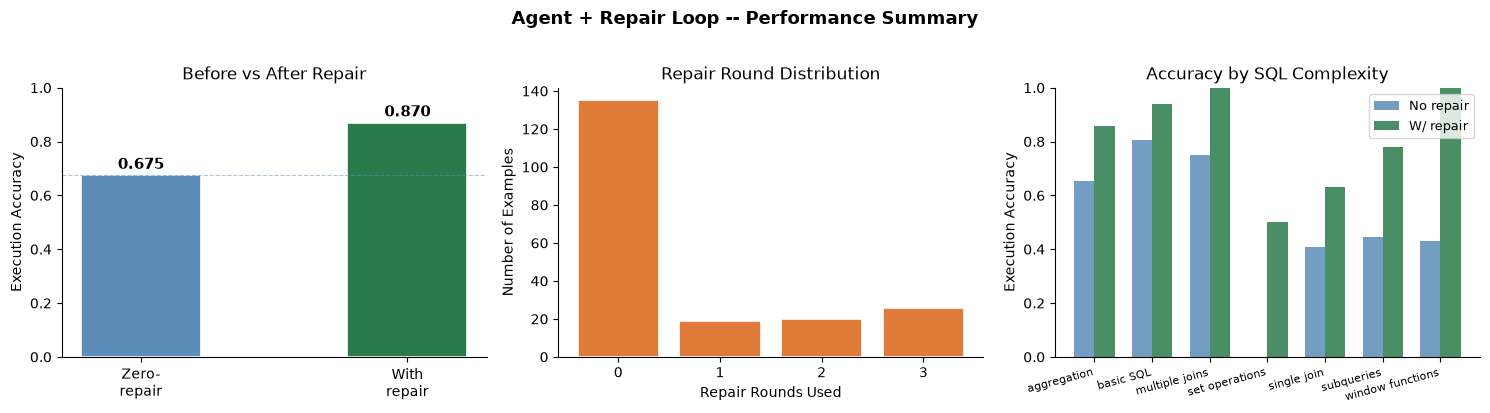

Saved -> agent_repair_summary.png


In [94]:
#matplotlib visualisation of repair impact
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Left: exec accuracy before vs after repair
ax = axes[0]
labels = ['Zero-\nrepair', 'With\nrepair']
vals   = [acc_first, acc_final]
colors = ['#5b8db8', '#2a7a4b']
bars = ax.bar(labels, vals, color=colors, width=0.45, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_ylabel('Execution Accuracy')
ax.set_title('Before vs After Repair', fontsize=12)
ax.spines[['top','right']].set_visible(False)
ax.axhline(acc_first, color='#5b8db8', linestyle='--', linewidth=0.8, alpha=0.5)

# Middle: repair rounds distribution
ax = axes[1]
round_counts = agent_df.repair_rounds.value_counts().sort_index()
ax.bar(round_counts.index.astype(str), round_counts.values,
       color='#e07b39', edgecolor='white', linewidth=1.2)
ax.set_xlabel('Repair Rounds Used')
ax.set_ylabel('Number of Examples')
ax.set_title('Repair Round Distribution', fontsize=12)
ax.spines[['top','right']].set_visible(False)

# Right: accuracy by complexity
ax = axes[2]
comps = comp_table.index.tolist()
x = np.arange(len(comps)); w = 0.35
ax.bar(x - w/2, comp_table.acc_first.values,    w, label='No repair', color='#5b8db8', alpha=0.85)
ax.bar(x + w/2, comp_table.acc_repaired.values, w, label='W/ repair', color='#2a7a4b', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([c.replace('_',' ') for c in comps], rotation=15, ha='right', fontsize=8)
ax.set_ylabel('Execution Accuracy')
ax.set_title('Accuracy by SQL Complexity', fontsize=12)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.set_ylim(0, 1)

plt.suptitle('Agent + Repair Loop -- Performance Summary', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('agent_repair_summary.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved -> agent_repair_summary.png')

### 3.10 Failure Analysis

Inspect examples still wrong after all repair rounds and categorise them.

In [95]:
# failure categorisation

def _lower_or_empty(value):
    return '' if pd.isna(value) else str(value).lower()


def categorise_failure(row):
    err = _lower_or_empty(row['error'])
    pred = _lower_or_empty(row['pred'])
    if 'no such table' in err:
        return 'wrong_table_name'
    if 'no such column' in err:
        return 'wrong_column_name'
    if 'syntax error' in err:
        return 'syntax_error'
    if 'ambiguous' in err:
        return 'ambiguous_column'
    if err:
        return 'other_sql_error'
    if not row['correct']:
        if 'join' in pred:
            return 'wrong_join'
        if 'group by' in pred:
            return 'wrong_aggregation'
        return 'wrong_result'
    return 'correct'


failures = agent_df[~agent_df.correct].copy()
failures['failure_type'] = failures.apply(categorise_failure, axis=1)

print(f'Failed examples: {len(failures)} / {len(agent_df)}')
print('\nFailure categories:')
display(failures.failure_type.value_counts().rename('count').to_frame())

print('\n=== Sample Failures ===')
for _, row in failures.head(3).iterrows():
    err_val = row['error'] if not pd.isna(row['error']) else 'None'
    print(f"\n  ID        : {row['id']}")
    print(f"  Complexity: {row['complexity']}")
    print(f"  Q         : {str(row['question'])[:80]}")
    print(f"  Gold SQL  : {str(row['gold'])[:80]}")
    print(f"  Pred SQL  : {str(row['pred'])[:80]}")
    print(f'  Error     : {err_val}')
    print(f"  Category  : {row['failure_type']}")

Failed examples: 26 / 200

Failure categories:


,count
failure_type,
wrong_result,9
wrong_aggregation,7
wrong_join,5
wrong_column_name,4
other_sql_error,1



=== Sample Failures ===

  ID        : 3510
  Complexity: set operations
  Q         : What is the total number of mobile and broadband subscribers for each technology
  Gold SQL  : SELECT 'Mobile' AS source, technology, COUNT(*) AS total FROM mobile_subscribers
  Pred SQL  : SELECT technology, SUM(CASE WHEN region = 'North' THEN 1 ELSE 0 END) + SUM(CASE 
  Error     : None
  Category  : wrong_aggregation

  ID        : 4542
  Complexity: single join
  Q         : Find the total volume of timber sold in 2021
  Gold SQL  : SELECT SUM(ts.volume) FROM timber_sales ts INNER JOIN forests f ON ts.forest_id 
  Pred SQL  : SELECT SUM(t.volume) FROM timber_sales t WHERE strftime('%Y', t.year) = '2021';
  Error     : None
  Category  : wrong_result

  ID        : 2740
  Complexity: subqueries
  Q         : How many users have a heart rate over 120 BPM for more than 30 minutes in a work
  Gold SQL  : SELECT COUNT(*) FROM (SELECT UserID, SUM(Duration) FROM WorkoutData WHERE AvgHea
  Pred SQL  : S

### 3.11 * Majority Voting (Extra Credit)

Generate N independent SQL candidates, execute all, and pick the result
that the majority agrees on (by result hash). Runs only when `MAJORITY_VOTE=True`.

*Source: 4_Structured_Generation_Lab §3.2 — majority voting at scale.*

In [96]:
#  majority-vote extension following 4_Structured_Generation_Lab §3.2
# FIXED: temperature only passed when do_sample=True; safe_rows guards None
import hashlib

def result_hash(rows):
    if not rows:
        return '__empty__'
    key = str(sorted([tuple(str(v) for v in row) for row in rows]))
    return hashlib.md5(key.encode()).hexdigest()[:12]

def agent_majority(question: str, sql_context: str, n: int = MAJORITY_N):
    examples   = _retrieve(question, sql_context)
    candidates = []
    vote_trace = []
    for i in range(n):
        use_sample = (i > 0)   # first candidate greedy; rest sampled
        msgs = build_messages(question, sql_context, examples=examples, style=PROMPT_STYLE)
        input_ids = llm_tok.apply_chat_template(
            msgs, add_generation_prompt=True, return_tensors='pt'
        ).to(device)
        gen_kwargs = dict(
            max_new_tokens=256, do_sample=use_sample,
            pad_token_id=llm_tok.eos_token_id,
        )
        if use_sample:
            gen_kwargs['temperature'] = 0.7   # FIXED: only set when do_sample=True
        with torch.no_grad():
            out = llm.generate(input_ids, **gen_kwargs)
        raw = llm_tok.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
        sql = re.sub(r'^```[a-z]*\n?', '', raw, flags=re.I).rstrip('` \n').strip()
        rows, err = run_sql(sql_context, sql)
        h = result_hash(rows) if err is None else f'__err_{i}__'
        candidates.append((sql, rows, err, h))
        vote_trace.append(f'[Vote {i+1}/{n}] SQL: {sql[:80]} | hash: {h}')

    hash_counts = {}
    for cand_sql, cand_rows, cand_err, cand_h in candidates:
        hash_counts[cand_h] = hash_counts.get(cand_h, 0) + 1
    best_hash = max(hash_counts, key=hash_counts.__getitem__)
    best_sql, best_rows, best_err, _ = next(
        (c for c in candidates if c[3] == best_hash), candidates[0]
    )
    safe_rows = best_rows or []   # FIXED: guard None
    if best_err:
        best_answer = f'Majority SQL failed: {best_err}'
    elif not safe_rows:
        best_answer = 'Majority result: no rows returned.'
    elif len(safe_rows)==1 and len(safe_rows[0])==1:
        best_answer = f'The answer is: {safe_rows[0][0]}'
    else:
        best_answer = f'Found {len(safe_rows)} row(s). First: {safe_rows[0]}'
    vote_trace.append(
        f'[VOTE RESULT] best hash: {best_hash} '
        f'(votes: {hash_counts[best_hash]}/{n}) | answer: {best_answer}'
    )
    return best_sql, best_answer, vote_trace

if MAJORITY_VOTE:
    print(f'Running majority-vote agent (N={MAJORITY_N}) on first 10 test examples ...')
    mv_rows = []
    for ex in list(test_eval)[:10]:
        t0 = _time.time()
        mv_sql, mv_answer, mv_trace = agent_majority(ex['sql_prompt'], ex['sql_context'])
        elapsed = _time.time() - t0
        pred_r, pred_e = run_sql(ex['sql_context'], mv_sql)
        gold_r, gold_e = run_sql(ex['sql_context'], ex['sql'])
        correct = (
            same_result(pred_r, gold_r)
            if (pred_e is None and gold_e is None
                and pred_r is not None and gold_r is not None)
            else False
        )
        mv_rows.append({'id': ex['id'], 'correct': correct, 'sec': round(elapsed, 2)})
        print(f"  {str(ex['id'])[:12]}  correct={correct}  sec={elapsed:.1f}")
    mv_acc = sum(r['correct'] for r in mv_rows) / len(mv_rows)
    print(f'\nMajority-vote accuracy (N={MAJORITY_N}, 10 examples): {mv_acc:.3f}')
    print('(Compare with agent_df.correct.mean() for the same examples)')
else:
    print('MAJORITY_VOTE=False -- skipped. Set MAJORITY_VOTE=True in cell 3.0 to run.')

MAJORITY_VOTE=False -- skipped. Set MAJORITY_VOTE=True in cell 3.0 to run.


### 3.12 `agent_fn` — Callable for Person 5 (Evaluation)

Person 5's `evaluate(system_fn, test_ds)` expects `fn(question, sql_context) -> sql_string`.

In [97]:
#thin adapter so evaluate.py can call agent() like generate()
def agent_fn(question: str, sql_context: str) -> str:
    final_sql, _, _ = agent(question, sql_context)
    return final_sql

def agent_fn_no_repair(question: str, sql_context: str) -> str:
    final_sql, _, _ = agent(question, sql_context, max_repairs=0)
    return final_sql

print('Exportable functions:')
print('  agent_fn           -> calls agent(q, ctx, max_repairs=3)')
print('  agent_fn_no_repair -> calls agent(q, ctx, max_repairs=0)')
print()
print('Usage by Person 5:')
print('  evaluate(agent_fn, test_ds)            # with repair')
print('  evaluate(agent_fn_no_repair, test_ds)  # ablation: 0 repairs')

Exportable functions:
  agent_fn           -> calls agent(q, ctx, max_repairs=3)
  agent_fn_no_repair -> calls agent(q, ctx, max_repairs=0)

Usage by Person 5:
  evaluate(agent_fn, test_ds)            # with repair
  evaluate(agent_fn_no_repair, test_ds)  # ablation: 0 repairs


### 3.13 Part 3 Runtime Summary

In [98]:
# runtime and file summary
import os

print('=' * 55)
print('  Part 3 -- Summary')
print('=' * 55)

files = {
    'results/agent_repair.json': 'per-example agent results',
    'agent_repair_summary.png':  'repair impact chart',
}
for path, desc in files.items():
    size = os.path.getsize(path) if os.path.exists(path) else -1
    tag  = f'{size:,} bytes' if size >= 0 else 'NOT FOUND'
    print(f'  {path:<35} {tag}  # {desc}')

print()
print('Key metrics:')
# FIXED: guard with try/except in case cell 3.8 was not yet run
try:
    print(f'  Exec accuracy WITHOUT repair : {acc_first:.3f}')
    print(f'  Exec accuracy WITH repair    : {acc_final:.3f}')
    print(f'  Repair success rate          : {repair_rate:.1%}')
    print(f'  Average repair rounds        : {avg_rounds:.2f}')
except NameError:
    print('  (Run cell 3.8 first to see metrics)')
print()
print('Exports for downstream parts:')
print('  agent()              -> (sql, answer, trace)')
print('  agent_fn(q, ctx)     -> sql  [for Person 5]')
print('  agent_fn_no_repair() -> sql  [ablation]')

  Part 3 -- Summary
  results/agent_repair.json           188,138 bytes  # per-example agent results
  agent_repair_summary.png            89,847 bytes  # repair impact chart

Key metrics:
  Exec accuracy WITHOUT repair : 0.675
  Exec accuracy WITH repair    : 0.870
  Repair success rate          : 60.0%
  Average repair rounds        : 0.69

Exports for downstream parts:
  agent()              -> (sql, answer, trace)
  agent_fn(q, ctx)     -> sql  [for Person 5]
  agent_fn_no_repair() -> sql  [ablation]


# Part 4: LoRA Fine-tuning and Evaluation

This section adds LoRA model training and direct SQL-generation evaluation to the Part 3 agent notebook. The Part 3 agent code above is unchanged.

### How to run

1. Run the LoRA code-definition cell below.
2. Leave `RUN_LORA_EXPERIMENTS = False` to inspect the saved 5k/10k test results.
3. Set it to `True` to train and evaluate all four model/data-size combinations. This takes time and requires a CUDA GPU. New adapters are saved under `notebook_adapters/`, keeping existing adapter folders untouched.

### 4.1 LoRA model code

Training, prompt construction, generation, and evaluation functions from `finetune.py` are included here so they can be run from this notebook.

In [1]:
from config import CONFIG, SEED, set_seed
import data
# Part 4: Fine-tuning Qwen2.5-0.5B with LoRA (PEFT).
import os, sys, time, json, re, torch
from collections import defaultdict
from transformers import (AutoTokenizer, AutoModelForCausalLM, Trainer,
                          TrainingArguments, DataCollatorForSeq2Seq, TrainerCallback)
from peft import LoraConfig, get_peft_model, PeftModel
BASE = CONFIG["lora_base"]
ADAPTER = CONFIG["adapter_path"]
MAX_LEN = 512
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]

SQLITE_RULE = ("### Instructions:\nWrite one SQLite SELECT query. Use only SQLite syntax: "
               "strftime() or string comparison for dates, no YEAR(), MONTH(), DATE_FORMAT() "
               "or other MySQL functions. Use only the tables and columns in the schema.\n\n")

def build_prompt(question, schema, style="plain"):
    # Used for BOTH training and generation. If you edit it, retrain the adapter.
    # style="sqlite" adds the SQLite-only rule; the style is saved with the adapter.
    head = SQLITE_RULE if style == "sqlite" else ""
    return f"{head}### Schema:\n{schema}\n\n### Question:\n{question}\n\n### SQL:\n"

def prompt_of(adapter):
    """Prompt style an adapter was trained with (prompt_style.txt); 'plain' if missing."""
    p = os.path.join(adapter or "", "prompt_style.txt")
    return open(p).read().strip() if adapter and os.path.exists(p) else "plain"

def _encode(ex, tok, style="plain"):
    p_ids = tok(build_prompt(ex["sql_prompt"], ex["sql_context"], style),
                add_special_tokens=False)["input_ids"]
    a_ids = tok(ex["sql"] + tok.eos_token, add_special_tokens=False)["input_ids"]
    ids = p_ids + a_ids
    return {"input_ids": ids, "attention_mask": [1] * len(ids),
            "labels": [-100] * len(p_ids) + a_ids}      # loss only on the SQL

def get_val(train_ds, start=5000, size=50):
    """Validation examples from the train split, never used for training."""
    return train_ds.shuffle(seed=SEED).select(range(start, start + size))

class TxtLogger(TrainerCallback):
    """Appends every Trainer log (loss, lr, grad_norm, ...) to a txt file as training runs."""
    def __init__(self, path, header=""):
        self.path = path
        with open(path, "a", encoding="utf-8") as f:
            f.write(f"\n=== {time.strftime('%Y-%m-%d %H:%M:%S')} {header}\n")

    def on_log(self, args, state, control, logs=None, **kw):
        with open(self.path, "a", encoding="utf-8") as f:
            f.write(f"step {state.global_step}/{state.max_steps}  {json.dumps(logs)}\n")

def train_lora(train_ds, n=1000, epochs=2, r=16, lr=2e-4,
               targets=TARGETS, adapter=ADAPTER,
               batch_size=4, grad_accum=4, grad_ckpt=False, log_file=None,
               base=BASE, dtype=torch.float32, prompt="plain", max_len=MAX_LEN):
    # batch_size/grad_accum/grad_ckpt: lower memory on small GPUs (8 GB) without
    # changing the effective batch size (batch_size * grad_accum).
    # log_file: if given, training logs are written there live (TxtLogger).
    # base/dtype: e.g. base=CONFIG["llm"] (Coder-1.5B) with dtype=torch.bfloat16 to fit 8 GB.
    set_seed()
    tok = AutoTokenizer.from_pretrained(base)
    ds = train_ds.shuffle(seed=SEED).select(range(n))
    ds = ds.map(lambda ex: _encode(ex, tok, prompt), remove_columns=ds.column_names)
    before = len(ds)
    ds = ds.filter(lambda ex: len(ex["input_ids"]) <= max_len)
    print(f"kept {len(ds)} of {before} examples (rest longer than {max_len} tokens)")

    model = AutoModelForCausalLM.from_pretrained(base, torch_dtype=dtype).to("cuda")
    cfg = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05,
                     target_modules=targets, task_type="CAUSAL_LM")
    model = get_peft_model(model, cfg)
    model.print_trainable_parameters()

    bf16 = torch.cuda.is_bf16_supported()
    args = TrainingArguments(
        output_dir="lora_out", per_device_train_batch_size=batch_size,
        gradient_accumulation_steps=grad_accum, learning_rate=lr,
        gradient_checkpointing=grad_ckpt,
        gradient_checkpointing_kwargs={"use_reentrant": False} if grad_ckpt else None,
        num_train_epochs=epochs, logging_steps=5, save_strategy="no",
        bf16=bf16, fp16=not bf16, report_to="none", seed=SEED)
    callbacks = [TxtLogger(log_file, f"n={n} r={r} lr={lr} epochs={epochs} "
                           f"targets={targets} batch={batch_size}x{grad_accum} "
                           f"max_len={max_len} base={base} adapter={adapter} "
                           f"prompt={prompt}")] if log_file else []
    Trainer(model=model, args=args, train_dataset=ds, callbacks=callbacks,
            data_collator=DataCollatorForSeq2Seq(tok, padding=True,
                                                 label_pad_token_id=-100)).train()
    model.save_pretrained(adapter)
    tok.save_pretrained(adapter)
    with open(os.path.join(adapter, "prompt_style.txt"), "w") as f:
        f.write(prompt)
    print("saved to", adapter)

def base_of(adapter):
    """Base model an adapter was trained on (from adapter_config.json); BASE if unknown."""
    cfg = os.path.join(adapter or "", "adapter_config.json")
    if adapter and os.path.exists(cfg):
        with open(cfg) as f:
            return json.load(f).get("base_model_name_or_path", BASE)
    return BASE

_cache = {}
def _load(adapter=None, base=None):
    base = base or base_of(adapter)
    key = (base, adapter or "base")
    if key not in _cache:
        tok = AutoTokenizer.from_pretrained(base)
        tok.padding_side = "left"
        model = AutoModelForCausalLM.from_pretrained(base, torch_dtype=torch.float16).to("cuda")
        if adapter:                       # adapter=None -> plain base model ("before")
            model = PeftModel.from_pretrained(model, adapter)
        _cache[key] = (tok, model.eval())
    return _cache[key]

def generate_lora(question, schema, adapter=ADAPTER, max_new_tokens=256, stop=(";",),
                  clean=True, base=None, prompt=None):
    """Same inputs/output as rag.generate(question, schema): returns one SQL string.
    stop=(';',) ends generation after the first statement (much faster);
    clean=True strips ```sql fences / extra text. Pass stop=None, clean=False for raw output.
    The base model and prompt style are read from the adapter; base=/prompt= override them."""
    tok, model = _load(adapter, base)
    style = prompt or prompt_of(adapter)
    inputs = tok(build_prompt(question, schema, style), return_tensors="pt").to("cuda")
    extra = {"stop_strings": list(stop), "tokenizer": tok} if stop else {}
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id, **extra)
    text = tok.decode(out[0][inputs["input_ids"].shape[1]:],
                      skip_special_tokens=True).strip()
    return clean_sql(text) if clean else text

def setup_lora(train_ds=None, n=None, adapter=ADAPTER, **kw):
    """Notebook entry point. config.TRAIN=True -> train and save the adapter;
    TRAIN=False -> just load the saved adapter (download lora_adapter/ from Drive first)."""
    import os
    from config import TRAIN
    if TRAIN:
        assert train_ds is not None, "TRAIN=True needs train_ds"
        train_lora(train_ds, n=n or CONFIG["lora_train_size"], adapter=adapter, **kw)
    elif not os.path.exists(os.path.join(adapter, "adapter_model.safetensors")):
        raise FileNotFoundError(f"{adapter} not found: download the adapter from Drive "
                                "into the repo folder, or set TRAIN=True in config.py")
    _load(adapter)
    print("LoRA adapter ready:", adapter)
    return adapter

def eval_lora(ds, adapter=ADAPTER):
    """adapter=None evaluates the base model without LoRA (the 'before' number)."""
    from data import run_sql, same_result          # Person 1's functions
    ok = 0
    for ex in ds:
        pred = generate_lora(ex["sql_prompt"], ex["sql_context"], adapter)
        p_rows, err = run_sql(ex["sql_context"], pred)
        g_rows, _ = run_sql(ex["sql_context"], ex["sql"])
        ok += (err is None) and same_result(p_rows, g_rows)
    return ok / len(ds)

def _norm_sql(s):
    return re.sub(r"\s+", " ", s.strip().rstrip(";")).lower()

def clean_sql(text):
    """Pull the first SQL statement out of model output: drops ```sql fences,
    trailing '### ...' sections and anything after the first ';'."""
    m = re.search(r"```(?:sql)?\s*(.*?)(```|$)", text, re.S | re.I)
    if m:
        text = m.group(1)
    text = text.split("###")[0]
    if ";" in text:
        text = text[:text.index(";") + 1]
    return text.strip()

def eval_lora_detailed(ds, adapter=ADAPTER, out_txt=None, name=None, base=None, prompt=None,
                       out_json=None):
    """Test-set metrics: execution accuracy, exact match, valid-SQL rate,
    accuracy by sql_complexity and latency. Writes one line per example to
    out_txt as it goes, then a summary. adapter=None -> base model.
    out_json: if given, the full predicted SQL per example is saved there (query_match.py).
    Same post-processing (stop at ';' + clean_sql) for base and LoRA, so it's fair."""
    from data import run_sql, same_result
    name = name or (adapter or "base")
    f = open(out_txt, "a", encoding="utf-8") if out_txt else None
    def w(line):
        print(line, flush=True)
        if f:
            f.write(line + "\n"); f.flush()

    w(f"\n=== {time.strftime('%Y-%m-%d %H:%M:%S')} eval {name} on {len(ds)} examples")
    n_exec = n_em = n_valid = n_gold_ok = 0
    by_cx = defaultdict(lambda: [0, 0])          # complexity -> [correct, total]
    secs, records = [], []
    for i, ex in enumerate(ds):
        t0 = time.time()
        pred = generate_lora(ex["sql_prompt"], ex["sql_context"], adapter, base=base,
                             prompt=prompt)
        secs.append(time.time() - t0)
        p_rows, err = run_sql(ex["sql_context"], pred)
        g_rows, g_err = run_sql(ex["sql_context"], ex["sql"])
        exec_ok = err is None and g_err is None and same_result(p_rows, g_rows)
        em = _norm_sql(pred) == _norm_sql(ex["sql"])
        n_exec += exec_ok; n_em += em; n_valid += err is None; n_gold_ok += g_err is None
        cx = ex.get("sql_complexity", "unknown")
        by_cx[cx][0] += exec_ok; by_cx[cx][1] += 1
        records.append({"id": ex["id"], "complexity": cx, "question": ex["sql_prompt"],
                        "pred": pred, "gold": ex["sql"], "error": err,
                        "correct": bool(exec_ok)})
        w(f"[{i+1}/{len(ds)}] exec={int(exec_ok)} em={int(em)} {secs[-1]:.1f}s "
          f"running_acc={n_exec/(i+1):.3f} cx={cx}"
          + (f" err={err[:80]}" if err else "") + f" | pred: {pred[:150]!r}")

    n = len(ds)
    m = {"system": name, "n_eval": n,
         "exec_acc": round(n_exec / n, 4), "exact_match": round(n_em / n, 4),
         "valid_sql": round(n_valid / n, 4), "gold_runs": round(n_gold_ok / n, 4),
         "sec_per_example": round(sum(secs) / n, 2),
         "by_complexity": {k: {"acc": round(c / t, 4), "n": t}
                           for k, (c, t) in sorted(by_cx.items())}}
    w("SUMMARY " + json.dumps(m, indent=2))
    if f:
        f.close()
    if out_json:
        with open(out_json, "w", encoding="utf-8") as jf:
            json.dump(records, jf, indent=1)
    return m


W1030 23:13:08.143546 25824 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


### 4.2 Train and evaluate 0.5B/1.5B models with 5k/10k examples

In [2]:
import gc
from pathlib import Path

RUN_LORA_EXPERIMENTS = False
LORA_EXPERIMENTS = [
    {"size": "0.5B", "base": CONFIG["lora_base"], "dtype": torch.float32, "n": 5000, "name": "0_5b_5k"},
    {"size": "0.5B", "base": CONFIG["lora_base"], "dtype": torch.float32, "n": 10000, "name": "0_5b_10k"},
    {"size": "1.5B", "base": CONFIG["llm"], "dtype": torch.bfloat16, "n": 5000, "name": "1_5b_5k"},
    {"size": "1.5B", "base": CONFIG["llm"], "dtype": torch.bfloat16, "n": 10000, "name": "1_5b_10k"},
]

if RUN_LORA_EXPERIMENTS:
    RESULTS.mkdir(exist_ok=True)
    train_ds, _, test_ds = data.get_splits(quick_run=False)

    for exp in LORA_EXPERIMENTS:
        adapter_path = Path("notebook_adapters") / f"lora_{exp['name']}"
        if adapter_path.exists() and any(adapter_path.iterdir()):
            raise FileExistsError(f"Adapter already exists; choose a new output folder: {adapter_path}")

        print(f"\nTraining {exp['size']} using {exp['n']:,} examples")
        train_lora(
            train_ds, n=exp["n"], epochs=1, r=16, lr=2e-4,
            adapter=str(adapter_path), batch_size=2, grad_accum=8,
            grad_ckpt=True, log_file=RESULTS / "notebook_lora_train_log.txt",
            base=exp["base"], dtype=exp["dtype"], max_len=512,
        )

        gc.collect()
        torch.cuda.empty_cache()
        metrics = eval_lora_detailed(
            test_ds, adapter=str(adapter_path),
            name=f"LoRA {exp['size']} ({exp['n']:,} examples)",
            base=exp["base"],
            out_txt=RESULTS / f"notebook_lora_{exp['name']}_test.txt",
            out_json=RESULTS / f"notebook_lora_{exp['name']}_predictions.json",
        )
        metrics_file = RESULTS / f"notebook_lora_{exp['name']}_metrics.json"
        metrics_file.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
else:
    print("LoRA experiments skipped. Set RUN_LORA_EXPERIMENTS = True to train and evaluate.")

LoRA experiments skipped. Set RUN_LORA_EXPERIMENTS = True to train and evaluate.


### 4.3 Compare the saved 5k/10k test metrics

This cell reads the four existing evaluation results; it does not load models or retrain.

In [3]:
from pathlib import Path
import json

RESULTS = Path("results")
RESULT_FILES = [
    ("0.5B", 5000, "lora_adapter_5k"),
    ("0.5B", 10000, "lora_adapter_10k"),
    ("1.5B", 5000, "lora_adapter_coder5k"),
    ("1.5B", 10000, "lora_adapter_coder10k"),
]

comparison = []
for model_size, train_size, adapter_name in RESULT_FILES:
    metrics_path = RESULTS / f"lora_metrics_{adapter_name}_test.json"
    if not metrics_path.exists():
        print(f"Saved metrics not found: {metrics_path}")
        continue
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    comparison.append({
        "Model": model_size,
        "Train examples": train_size,
        "Test examples": metrics["n_eval"],
        "Execution accuracy": metrics["exec_acc"],
        "Exact match": metrics["exact_match"],
        "Valid SQL": metrics["valid_sql"],
    })

for result in comparison:
    print(result)

{'Model': '0.5B', 'Train examples': 5000, 'Test examples': 200, 'Execution accuracy': 0.605, 'Exact match': 0.285, 'Valid SQL': 0.955}
{'Model': '0.5B', 'Train examples': 10000, 'Test examples': 200, 'Execution accuracy': 0.655, 'Exact match': 0.31, 'Valid SQL': 0.935}
{'Model': '1.5B', 'Train examples': 5000, 'Test examples': 200, 'Execution accuracy': 0.69, 'Exact match': 0.33, 'Valid SQL': 0.975}
{'Model': '1.5B', 'Train examples': 10000, 'Test examples': 200, 'Execution accuracy': 0.715, 'Exact match': 0.36, 'Valid SQL': 0.97}


### 4.4 Results by SQL complexity

This table and chart compare direct LoRA generation accuracy for each complexity type. `n` is the number of test examples in that category. These are direct-generation metrics, so there are no repair-round columns here; repair statistics are reported in Part 3.

model,n,0.5B ? 10k,0.5B ? 5k,1.5B ? 10k,1.5B ? 5k
complexity,,,,,
aggregation,49,57.1%,49.0%,61.2%,61.2%
basic SQL,102,82.3%,78.4%,87.2%,83.3%
multiple_joins,4,25.0%,50.0%,100.0%,100.0%
set operations,2,0.0%,0.0%,0.0%,0.0%
single join,27,51.8%,48.1%,63.0%,55.6%
subqueries,9,44.4%,22.2%,22.2%,33.3%
window functions,7,0.0%,0.0%,14.3%,14.3%


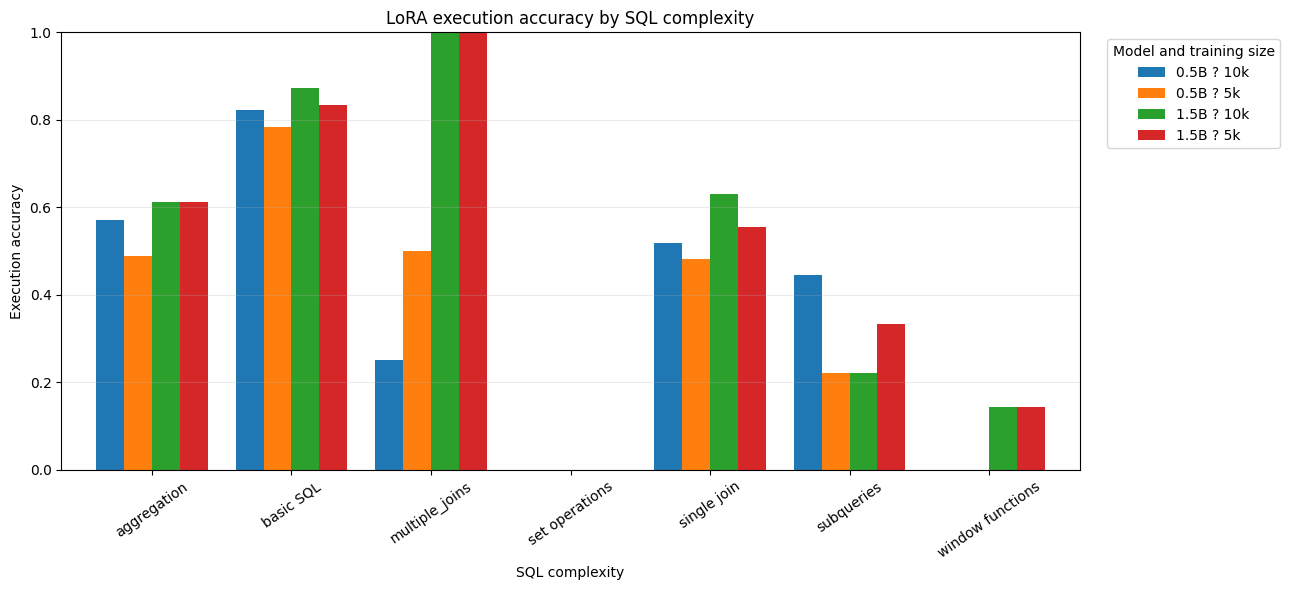

In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

results_dir = Path("results")
models_to_show = [
    ("0.5B ? 5k", "lora_adapter_5k"),
    ("0.5B ? 10k", "lora_adapter_10k"),
    ("1.5B ? 5k", "lora_adapter_coder5k"),
    ("1.5B ? 10k", "lora_adapter_coder10k"),
]

accuracy_rows = []
counts = {}
for model_name, adapter_name in models_to_show:
    metrics_file = results_dir / f"lora_metrics_{adapter_name}_test.json"
    if not metrics_file.exists():
        print(f"Metrics not found: {metrics_file}. Run the LoRA evaluation first.")
        continue

    metrics = json.loads(metrics_file.read_text(encoding="utf-8"))
    for complexity, values in metrics["by_complexity"].items():
        counts[complexity] = values["n"]
        accuracy_rows.append({
            "complexity": complexity,
            "model": model_name,
            "execution_accuracy": values["acc"],
        })

if accuracy_rows:
    accuracy = pd.DataFrame(accuracy_rows)
    accuracy_table = accuracy.pivot(
        index="complexity", columns="model", values="execution_accuracy"
    )
    accuracy_table.insert(0, "n", pd.Series(counts))
    accuracy_table = accuracy_table.rename_axis("complexity")
    display(accuracy_table.style.format({column: "{:.1%}" for column in accuracy_table.columns if column != "n"}))

    accuracy_plot = accuracy_table.drop(columns="n").plot(
        kind="bar", figsize=(13, 6), ylim=(0, 1), width=0.8
    )
    accuracy_plot.set_title("LoRA execution accuracy by SQL complexity")
    accuracy_plot.set_xlabel("SQL complexity")
    accuracy_plot.set_ylabel("Execution accuracy")
    accuracy_plot.legend(title="Model and training size", bbox_to_anchor=(1.02, 1), loc="upper left")
    accuracy_plot.tick_params(axis="x", rotation=35)
    accuracy_plot.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No saved per-complexity metrics to display yet.")